# **Install Dependencies**



 *This step installs the Python libraries required for the project, including PyTorch, CLIP, SentenceTransformer, NLTK, NetworkX, and ConceptNet-lite. These libraries support image and text feature extraction, knowledge graph construction, graph-based learning, multimodal fusion, and model evaluation.*

In [1]:
!pip install -q kaggle
!pip install -q transformers
!pip install -q torch torchvision
!pip install -q open-clip-torch
!pip install -q sentence-transformers
!pip install -q scikit-learn networkx numpy pandas matplotlib pillow
!pip install -q nltk
!pip install conceptnet-lite
print('All packages installed.')

  Attempting uninstall: peewee
    Found existing installation: peewee 4.5.3
    Uninstalling peewee-4.5.3:
      Successfully uninstalled peewee-4.5.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [conceptnet-lite]
All packages installed.


# **Feasibility Check**

*This step checks the available GPU, VRAM, and system RAM to determine whether the required models can run. It also selects an appropriate training sample size based on the available resources.*

In [2]:
import torch
import psutil
import os

print('=' * 55)
print('  FEASIBILITY CHECK')
print('=' * 55)

# GPU
if torch.cuda.is_available():
    DEVICE = 'cuda'
    gpu_name  = torch.cuda.get_device_name(0)
    vram_total = torch.cuda.get_device_properties(0).total_memory / 1e9
    vram_free  = (torch.cuda.get_device_properties(0).total_memory
                  - torch.cuda.memory_allocated(0)) / 1e9
    print(f'  GPU        : {gpu_name}')
    print(f'  VRAM total : {vram_total:.1f} GB')
    print(f'  VRAM free  : {vram_free:.1f} GB')
    clip_ok = vram_free >= 1.0
    print(f'  CLIP load  : {"OK" if clip_ok else "WARNING: low VRAM"}')
else:
    DEVICE = 'cpu'
    clip_ok = True
    print('  GPU        : Not available — using CPU')
    print('  CLIP load  : OK (CPU mode, slower)')

# RAM
ram = psutil.virtual_memory()
ram_free_gb = ram.available / 1e9
print(f'  RAM free   : {ram_free_gb:.1f} GB')
text_ok = ram_free_gb >= 0.5
print(f'  Text encoder load  : {"OK" if text_ok else "WARNING: low RAM"}')

# Select safe training size
if ram_free_gb >= 8 and DEVICE == 'cuda':
    TRAIN_SIZE = 500
elif ram_free_gb >= 4:
    TRAIN_SIZE = 300
else:
    TRAIN_SIZE = 150

print(f'  TRAIN_SIZE : {TRAIN_SIZE} (auto-selected based on memory)')
print('=' * 55)

if not (clip_ok and text_ok):
    print('WARNING: Low memory detected. Reduce TRAIN_SIZE manually if OOM occurs.')

  FEASIBILITY CHECK
  GPU        : Tesla T4
  VRAM total : 15.6 GB
  VRAM free  : 15.6 GB
  CLIP load  : OK
  RAM free   : 12.0 GB
  Text encoder load  : OK
  TRAIN_SIZE : 500 (auto-selected based on memory)


#  Download Dataset

*The Flickr30k dataset is downloaded from Kaggle and extracted into the working environment. The dataset provides images and their corresponding captions for multimodal feature extraction.*

In [3]:

import os
import subprocess
import zipfile

print("=" * 55)
print("          FLICKR30K DATASET SETUP")
print("=" * 55)

dataset = "eeshawn/flickr30k"
zip_path = "/content/flickr30k.zip"

# Step 1: Kaggle credentials (optional)
print("\n[1/3] Checking Kaggle configuration...")

if os.path.exists("/content/kaggle.json"):
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    subprocess.run(
        ["cp", "/content/kaggle.json",
         os.path.expanduser("~/.kaggle/kaggle.json")],
        check=True
    )
    os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
    print("Kaggle credentials configured.")
else:
    print("No local kaggle.json found. Using existing Kaggle authentication.")

# Step 2: Download dataset
print("\n[2/3] Downloading dataset...")

if os.path.exists(zip_path):
    print("Dataset ZIP already exists. Skipping download.")
else:
    subprocess.run(
        ["kaggle", "datasets", "download",
         "-d", dataset, "-p", "/content", "--quiet"],
        check=True
    )
    print("Dataset download completed.")

# Step 3: Extract dataset
print("\n[3/3] Extracting dataset...")

if not os.path.exists(zip_path):
    raise FileNotFoundError("Dataset ZIP file not found.")

with zipfile.ZipFile(zip_path, "r") as z:
    members = z.namelist()
    missing = [
        name for name in members
        if not os.path.exists(os.path.join("/content", name))
    ]
    if missing:
        z.extractall("/content")
        print("Dataset extraction completed.")
    else:
        print("Dataset files already extracted.")

print("\n" + "=" * 55)
print("             DATASET SETUP ")
print("=" * 55)
print("Dataset       : Flickr30k")
print("Source        : Kaggle")
print(f"Archive size  : {os.path.getsize(zip_path) / (1024**3):.2f} GB")
print(f"Archive files : {len(members)}")
print("Status        : SUCCESS")
print("=" * 55)


          FLICKR30K DATASET SETUP

[1/3] Checking Kaggle configuration...
No local kaggle.json found. Using existing Kaggle authentication.

[2/3] Downloading dataset...
Dataset download completed.

[3/3] Extracting dataset...
Dataset extraction completed.

             DATASET SETUP SUMMARY
Dataset       : Flickr30k
Source        : Kaggle
Archive size  : 4.08 GB
Archive files : 31784
Status        : SUCCESS


# Load dataset

*The caption file is loaded using Pandas to examine the dataset structure, number of records, and available columns. This helps verify the data before preprocessing.*

In [4]:
import os, re, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')
from PIL import Image

df = pd.read_csv('captions.txt', sep='|')
df.columns = df.columns.str.strip()
print('Dataset shape:', df.shape)
print('Columns:', df.columns.tolist())
print(df.head())

Dataset shape: (158915, 1)
Columns: ['image_name,comment_number,comment']
                   image_name,comment_number,comment
0  1000092795.jpg,0,Two young guys with shaggy ha...
1  1000092795.jpg,1,Two young  White males are ou...
2  1000092795.jpg,2,Two men in green shirts are s...
3  1000092795.jpg,3,A man in a blue shirt standin...
4  1000092795.jpg,4,Two friends enjoy time spent ...


# Sample Input Image

*A sample image and its corresponding caption are selected from the dataset. This example is used to demonstrate the visual and textual feature extraction processes.*

Image : 1000344755.jpg
Caption: Someone in a blue shirt and hat is standing on stair and leaning against a window .


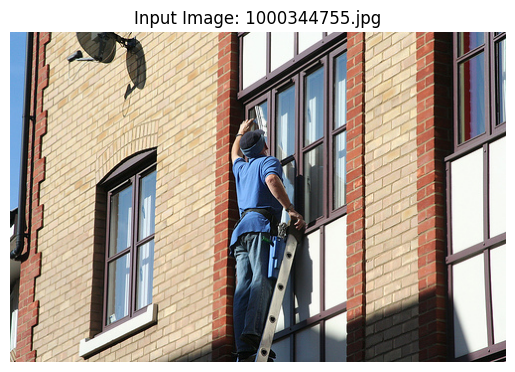

In [6]:
import os
from PIL import Image
import matplotlib.pyplot as plt

# Select sample image
row = df.iloc[15]
combined_string = row[df.columns[0]].strip()

parts = combined_string.split(',', 2)
image_name = parts[0].strip()
caption = parts[2].strip() if len(parts) > 2 else ''

# 4. Display the image and caption
img_path = os.path.join('flickr30k_images', image_name)
print(f'Image : {image_name}')
print(f'Caption: {caption}')

img = Image.open(img_path)
plt.imshow(img)
plt.axis('off')
plt.title(f'Input Image: {image_name}')
plt.show()

# Text Features Extraction

*The SentenceTransformer model, all-MiniLM-L6-v2, converts image captions into 384-dimensional semantic embeddings. A keyword extraction function also removes unnecessary words and generates candidate hashtags from the captions.*

In [9]:

import time
import re
import os
import logging
from sentence_transformers import SentenceTransformer
from huggingface_hub.utils import disable_progress_bars

# Reduce Hugging Face download progress messages
disable_progress_bars()
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)

print("=" * 60)
print("        TEXT ENCODER AND HASHTAG EXTRACTION")
print("=" * 60)

# ============================================================
# 1. LOAD SENTENCE TRANSFORMER
# ============================================================

MODEL_NAME = "all-MiniLM-L6-v2"

print("\n[1/3] Loading SentenceTransformer...")

t0 = time.time()
text_encoder = SentenceTransformer(MODEL_NAME)
loading_time = time.time() - t0

print(f"Model          : {MODEL_NAME}")
print(f"Loading time   : {loading_time:.2f} seconds")
print("Status         : SUCCESS")

# ============================================================
# 2. GENERATE TEXT EMBEDDING
# ============================================================

print("\n[2/3] Generating sample caption embedding...")

text_embedding = text_encoder.encode(
    caption,
    convert_to_numpy=True
)

print(f"Caption        : {caption}")
print(f"Embedding shape: {text_embedding.shape}")
print(f"Embedding dim  : {text_embedding.shape[0]}")
print("Status         : SUCCESS")

# ============================================================
# 3. CLEAN HASHTAG / KEYWORD EXTRACTION
# ============================================================

STOPWORDS = {
    'a', 'the', 'is', 'in', 'on', 'and', 'of', 'with', 'to', 'an',
    'up', 'down', 'into', 'out', 'are', 'be', 'at', 'by', 'was',
    'were', 'he', 'she', 'they', 'it', 'his', 'her', 'their', 'its',
    'that', 'this', 'which', 'who', 'what', 'from', 'for', 'as',
    'not', 'but', 'or', 'so', 'if', 'then', 'than', 'also',
    'has', 'have', 'had',

    'while', 'through', 'around', 'along', 'across', 'against',
    'after', 'before', 'between', 'among', 'under', 'over',
    'near', 'beside', 'behind', 'inside', 'outside',

    'some', 'someone', 'somebody', 'something',
    'another', 'other', 'others',
    'there', 'here',
    'few', 'many', 'several',
    'one',

    'look', 'looks', 'looking',
    'doing', 'does', 'done',
    'make', 'makes', 'making',
    'work', 'works', 'working',
    'appears', 'appearing',
    'seems', 'seem'
}

def extract_keywords(text):

    words = re.findall(
        r'\b[a-zA-Z]+\b',
        str(text).lower()
    )

    keywords = []

    for word in words:

        if word in STOPWORDS:
            continue

        if len(word) <= 2:
            continue

        if word not in keywords:
            keywords.append(word)

    return keywords


def to_hashtags(text):

    return [
        '#' + word
        for word in extract_keywords(text)
    ]


print("\n[3/3] Initializing hashtag extractor...")

sample_keywords = extract_keywords(caption)
sample_hashtags = to_hashtags(caption)

print(f"Keywords       : {sample_keywords}")
print(f"Hashtags       : {sample_hashtags}")





        TEXT ENCODER AND HASHTAG EXTRACTION

[1/3] Loading SentenceTransformer...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Model          : all-MiniLM-L6-v2
Loading time   : 1.70 seconds
Status         : SUCCESS

[2/3] Generating sample caption embedding...
Caption        : Someone in a blue shirt and hat is standing on stair and leaning against a window .
Embedding shape: (384,)
Embedding dim  : 384
Status         : SUCCESS

[3/3] Initializing hashtag extractor...
Keywords       : ['blue', 'shirt', 'hat', 'standing', 'stair', 'leaning', 'window']
Hashtags       : ['#blue', '#shirt', '#hat', '#standing', '#stair', '#leaning', '#window']


# **Multi-Caption Ground Truth**

*All available captions for the selected image are collected. Keywords extracted from these captions are combined to create a broader reference set of relevant hashtags for the sample image.*

In [10]:
# Multi-Caption Ground Truth
single_column_name = df.columns[0]
filtered_df = df[
    df[single_column_name].apply(lambda x: x.split(',', 1)[0].strip()) == image_name
]

# extract all captions from the filtered DataFrame
all_captions_for_image = []
for raw_entry in filtered_df[single_column_name].tolist():
    parts = raw_entry.split(',', 2)
    if len(parts) > 2:
        all_captions_for_image.append(parts[2].strip())

print(f'Image: {image_name}')
print(f'Found {len(all_captions_for_image)} captions:')
for idx, cap in enumerate(all_captions_for_image, 1):
    print(f'  [{idx}] {cap.strip()}')

# Build ground truth: union of keywords from all captions
multi_caption_true_tags = set()
for cap in all_captions_for_image:
    kws = extract_keywords(str(cap))
    multi_caption_true_tags.update(['#' + w for w in kws])

# Convert to sorted list for reproducibility
multi_caption_true_tags = sorted(list(multi_caption_true_tags))

# Define text_tags using the caption from the sample image
text_tags = to_hashtags(caption)

print(f'\nSingle-caption ground truth ({len(text_tags)} tags):')
print('  ' + ' '.join(text_tags))

print(f'\nMulti-caption ground truth ({len(multi_caption_true_tags)} tags):')
print('  ' + ' '.join(multi_caption_true_tags))

Image: 1000344755.jpg
Found 5 captions:
  [1] Someone in a blue shirt and hat is standing on stair and leaning against a window .
  [2] A man in a blue shirt is standing on a ladder cleaning a window .
  [3] A man on a ladder cleans the window of a tall building .
  [4] man in blue shirt and jeans on ladder cleaning windows
  [5] a man on a ladder cleans a window

Single-caption ground truth (7 tags):
  #blue #shirt #hat #standing #stair #leaning #window

Multi-caption ground truth (15 tags):
  #blue #building #cleaning #cleans #hat #jeans #ladder #leaning #man #shirt #stair #standing #tall #window #windows


#  Visual Features Extraction - CLIP Initialization

*The pretrained CLIP ViT-B/32 model is loaded to extract visual information from images. The model is configured to run on the available GPU or CPU.*

In [11]:
import open_clip

print(f'Loading CLIP ViT-B/32 on {DEVICE}...')
t0 = time.time()
clip_model, _, clip_preprocess = open_clip.create_model_and_transforms(
    'ViT-B-32', pretrained='openai'
)
clip_model = clip_model.to(DEVICE).eval()
tokenizer  = open_clip.get_tokenizer('ViT-B-32')
print(f'Loaded in {time.time()-t0:.1f}s')

# Check VRAM after load
if DEVICE == 'cuda':
    used = torch.cuda.memory_allocated(0) / 1e9
    print(f'VRAM used after CLIP load: {used:.2f} GB')

Loading CLIP ViT-B/32 on cuda...
Loaded in 6.1s
VRAM used after CLIP load: 0.89 GB


# **CLIP Visual Embedding**

*The sample image is processed using CLIP to generate a 512-dimensional visual embedding. This vector represents the image's visual features and is used in the multimodal recommendation pipeline.*

In [12]:
# CLIP visual embedding (512-dim)
img_tensor = clip_preprocess(img).unsqueeze(0).to(DEVICE)
with torch.no_grad():
    visual_embedding = clip_model.encode_image(img_tensor).cpu().numpy().flatten()
    visual_embedding = visual_embedding / (np.linalg.norm(visual_embedding) + 1e-8)
print(f'CLIP visual embedding shape: {visual_embedding.shape}')

CLIP visual embedding shape: (512,)


# **CLIP Zero-Shot Label Scoring**

*CLIP compares the image embedding with text representations of predefined candidate labels. Similarity scores are calculated and used to identify the top visual concepts associated with the image.*

In [14]:

# ============================================================
# CLIP ZERO-SHOT LABEL SCORING
# ============================================================

CANDIDATE_LABELS = [
    'person','man','woman','child','dog','cat','horse',
    'car','bicycle','tree','grass','water','sky','building',
    'road','mountain','beach','food','table','chair','sports',
    'running','jumping','playing','swimming','hiking','sitting',
    'crowd','indoor','outdoor','nature','urban','sunset','snow'
]

# ------------------------------------------------------------
# 1. Compute CLIP similarity scores
# ------------------------------------------------------------

text_inputs = tokenizer(
    [f'a photo of a {l}' for l in CANDIDATE_LABELS]
).to(DEVICE)

with torch.no_grad():
    label_features = clip_model.encode_text(text_inputs)
    label_features = label_features / label_features.norm(
        dim=-1, keepdim=True
    )

    img_feat = torch.tensor(
        visual_embedding
    ).unsqueeze(0).to(DEVICE)

    similarity = (img_feat @ label_features.T).squeeze(0)

    clip_probs = similarity.softmax(dim=0).cpu().numpy()

# ------------------------------------------------------------
# 2. Store CLIP scores for later ranking
# ------------------------------------------------------------

CLIP_SCORES = {
    CANDIDATE_LABELS[i]: float(clip_probs[i])
    for i in range(len(CANDIDATE_LABELS))
}

# ------------------------------------------------------------
# 3. Select top 5 visual concepts
# ------------------------------------------------------------

top5_idx = clip_probs.argsort()[::-1][:5]

visual_labels_clip = [
    CANDIDATE_LABELS[i] for i in top5_idx
]

visual_tags = [
    '#' + l for l in visual_labels_clip
]

# ------------------------------------------------------------
# 4. Display organized output
# ------------------------------------------------------------

print("=" * 58)
print("              CLIP ZERO-SHOT SCORING")
print("=" * 58)

print(f"\nTotal candidate labels : {len(CANDIDATE_LABELS)}")
print("Selection method       : Top-5 by CLIP score")

print("\nTOP 5 PREDICTED VISUAL CONCEPTS")
print("-" * 58)
print(f"{'Rank':<8}{'Concept':<20}{'CLIP Score':>12}")
print("-" * 58)

for rank, i in enumerate(top5_idx, start=1):
    print(
        f"{rank:<8}"
        f"{CANDIDATE_LABELS[i]:<20}"
        f"{clip_probs[i]:>12.4f}"
    )

print("-" * 58)
print(f"\nVisual hashtags : {', '.join(visual_tags)}")



              CLIP ZERO-SHOT SCORING

Total candidate labels : 34
Selection method       : Top-5 by CLIP score

TOP 5 PREDICTED VISUAL CONCEPTS
----------------------------------------------------------
Rank    Concept               CLIP Score
----------------------------------------------------------
1       man                       0.0305
2       building                  0.0305
3       urban                     0.0305
4       person                    0.0304
5       jumping                   0.0301
----------------------------------------------------------

Visual hashtags : #man, #building, #urban, #person, #jumping


# **ConceptNet Database Setup**

*The ConceptNet-lite database is initialized to retrieve semantic relationships between concepts. A sample label lookup is performed to verify that the knowledge graph database is accessible.*

In [19]:
import conceptnet_lite
import os
from peewee import DatabaseError

DB_PATH = '/content/conceptnet.db'
COMPRESSED_DB_PATH = '/content/conceptnet.db.zip'

try:
    # Try to connect to the existing database
    conceptnet_lite.connect(db_path=DB_PATH)
except (DatabaseError, Exception) as e:
    print(f"Database connection failed due to corruption or missing files: {e}")
    print("Removing corrupted database files to trigger a fresh download...")

    # Delete the malformed database and compressed ZIP if they exist
    if os.path.exists(DB_PATH):
        os.remove(DB_PATH)
    if os.path.exists(COMPRESSED_DB_PATH):
        os.remove(COMPRESSED_DB_PATH)

    # Re-attempt connection which will automatically download and initialize a clean database
    print("Re-connecting and downloading fresh ConceptNet database...")
    conceptnet_lite.connect(db_path=DB_PATH)

from conceptnet_lite import Label
try:
    # Test retrieving a simple label
    label_obj = Label.get(text='man', language='en')
    print("Found label:", label_obj)
    print("Concepts count:", len(label_obj.concepts))
except Exception as e:
    print("ConceptNet-lite query error:", type(e), e)

Database connection failed due to corruption or missing files: database disk image is malformed
Removing corrupted database files to trigger a fresh download...
Re-connecting and downloading fresh ConceptNet database...
File not found: /content/conceptnet.db
Download compressed database
[*] 0 bytes / 1.85 GB @ 0 bytes/s [------------------] [0.0%, 0s left]    [*] 0 bytes / 1.85 GB @ 0 bytes/s [------------------] [0.0%, 0s left]    [*] 488 kB / 1.85 GB @ 1.6 MB/s [------------------] [0.0%, 0s left]    [*] 3.4 MB / 1.85 GB @ 8.5 MB/s [------------------] [0.2%, 0s left]    [*] 11.5 MB / 1.85 GB @ 23.1 MB/s [------------------] [0.6%, 0s left]   


# **Knowledge Graph Expansion**

*Relevant concepts are expanded using WordNet and ConceptNet relationships. Semantic similarity filtering is applied to reduce unrelated concepts and retain knowledge that is useful for understanding the image and caption.*

In [20]:
# ============================================================
# CONTEXT-AWARE CLEAN DUAL-KG EXPANSION
# WordNet + ConceptNet + SentenceTransformer Semantic Filtering
# ============================================================

import re
import numpy as np
import nltk
from nltk.corpus import wordnet as wn
from sentence_transformers import util

nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)


# ============================================================
# 1. BASIC FILTERING
# ============================================================

GENERIC_CONCEPTS = {
    'thing', 'object', 'entity',
    'something', 'someone', 'somebody',
    'person', 'individual',
    'place', 'area',
    'activity', 'event',
    'time', 'way', 'part',
    'cause', 'evidence'
}


def normalize_concept(text):

    if text is None:
        return None

    text = str(text).lower().strip()
    text = text.replace('_', ' ')
    text = re.sub(r'\s+', ' ', text)

    # Keep normal English concept strings
    if not re.fullmatch(r"[a-zA-Z -]+", text):
        return None

    if len(text) < 3:
        return None

    # Avoid long ConceptNet phrases
    if len(text.split()) > 2:
        return None

    if text in GENERIC_CONCEPTS:
        return None

    return text


# ============================================================
# 2. WORDNET EXPANSION
# ============================================================

def wordnet_expand(word, max_synonyms=2, max_hypernyms=2):

    results = []

    word = normalize_concept(word)

    if word is None:
        return results

    # Noun -> Verb -> Adjective
    synsets = wn.synsets(word, pos=wn.NOUN)

    if not synsets:
        synsets = wn.synsets(word, pos=wn.VERB)

    if not synsets:
        synsets = wn.synsets(word, pos=wn.ADJ)

    if not synsets:
        return results

    # Main/first sense only
    primary = synsets[0]

    # -------------------------
    # Synonyms
    # -------------------------

    synonym_count = 0

    for lemma in primary.lemmas():

        concept = normalize_concept(lemma.name())

        if concept is None or concept == word:
            continue

        results.append({
            'input': word,
            'concept': concept,
            'kg_score': 0.90,
            'source': 'WordNet',
            'relation': 'Synonym'
        })

        synonym_count += 1

        if synonym_count >= max_synonyms:
            break

    # -------------------------
    # Direct hypernyms
    # -------------------------

    hypernym_count = 0

    for hyper in primary.hypernyms():

        for lemma in hyper.lemmas():

            concept = normalize_concept(lemma.name())

            if concept is None or concept == word:
                continue

            results.append({
                'input': word,
                'concept': concept,
                'kg_score': 0.75,
                'source': 'WordNet',
                'relation': 'Hypernym L1'
            })

            hypernym_count += 1

            if hypernym_count >= max_hypernyms:
                break

        if hypernym_count >= max_hypernyms:
            break

    return results


# ============================================================
# 3. CONCEPTNET EXPANSION
# ============================================================

CONCEPTNET_RELATION_SCORE = {
    'synonym': 0.90,
    'similar_to': 0.85,
    'is_a': 0.80,
    'has_property': 0.78
}


def conceptnet_expand_offline(word, max_results=4):

    results = []

    word_clean = normalize_concept(word)

    if word_clean is None:
        return results

    try:

        from conceptnet_lite import Label, Language, edges_for

        english = Language.get(name='en')

        label_obj = Label.get(
            text=word_clean,
            language=english
        )

        concepts = label_obj.concepts
        candidates = {}

        for edge in edges_for(
            concepts,
            same_language=True
        ):

            relation = str(edge.relation.name).lower()

            if relation not in CONCEPTNET_RELATION_SCORE:
                continue

            start_label = edge.start.text.lower().strip()
            end_label = edge.end.text.lower().strip()

            if start_label == word_clean:
                target = end_label

            elif end_label == word_clean:
                target = start_label

            else:
                continue

            target = normalize_concept(target)

            if target is None:
                continue

            if target == word_clean:
                continue

            score = CONCEPTNET_RELATION_SCORE[relation]

            relation_display = {
                'synonym': 'Synonym',
                'similar_to': 'SimilarTo',
                'is_a': 'IsA',
                'has_property': 'HasProperty'
            }[relation]

            if (
                target not in candidates
                or
                score > candidates[target]['kg_score']
            ):

                candidates[target] = {
                    'input': word_clean,
                    'concept': target,
                    'kg_score': score,
                    'source': 'ConceptNet',
                    'relation': relation_display
                }

        candidates = sorted(
            candidates.values(),
            key=lambda x: x['kg_score'],
            reverse=True
        )

        return candidates[:max_results]

    except Exception as e:

        print(
            f"[ConceptNet Debug] {word_clean}: "
            f"{type(e).__name__}: {e}"
        )

        return []


# ============================================================
# 4. GET ALL DUAL-KG CANDIDATES
# ============================================================

def universal_kg_expand(labels):

    all_edges = []

    for label in labels:

        word = (
            label.lower()
            .replace('_', ' ')
            .lstrip('#')
            .strip()
        )

        all_edges.extend(
            wordnet_expand(word)
        )

        all_edges.extend(
            conceptnet_expand_offline(word)
        )

    # Remove exact duplicates
    unique = {}

    for item in all_edges:

        key = (
            item['input'],
            item['concept'],
            item['source'],
            item['relation']
        )

        if (
            key not in unique
            or
            item['kg_score'] > unique[key]['kg_score']
        ):
            unique[key] = item

    return list(unique.values())


# ============================================================
# 5. SEMANTIC RELEVANCE FILTER
# ============================================================

def add_semantic_relevance(
    kg_edges,
    caption_text,
    threshold=0.35
):

    if len(kg_edges) == 0:
        return []

    # --------------------------------------------------------
    # Encode caption once
    # --------------------------------------------------------

    caption_embedding = text_encoder.encode(
        caption_text,
        convert_to_tensor=True,
        normalize_embeddings=True
    )

    # Cache repeated input words
    input_cache = {}

    # Cache candidate concepts
    concept_cache = {}

    filtered_edges = []

    for item in kg_edges:

        input_word = item['input']
        expanded_concept = item['concept']

        # ----------------------------------------------------
        # Encode original input concept
        # ----------------------------------------------------

        if input_word not in input_cache:

            input_cache[input_word] = text_encoder.encode(
                input_word,
                convert_to_tensor=True,
                normalize_embeddings=True
            )

        # ----------------------------------------------------
        # Encode expanded concept
        # ----------------------------------------------------

        if expanded_concept not in concept_cache:

            concept_cache[expanded_concept] = text_encoder.encode(
                expanded_concept,
                convert_to_tensor=True,
                normalize_embeddings=True
            )

        input_embedding = input_cache[input_word]
        concept_embedding = concept_cache[expanded_concept]

        # ----------------------------------------------------
        # Similarity:
        # expanded concept <-> original concept
        # ----------------------------------------------------

        input_similarity = float(
            util.cos_sim(
                concept_embedding,
                input_embedding
            ).item()
        )

        # ----------------------------------------------------
        # Similarity:
        # expanded concept <-> caption
        # ----------------------------------------------------

        caption_similarity = float(
            util.cos_sim(
                concept_embedding,
                caption_embedding
            ).item()
        )

        # ----------------------------------------------------
        # Combined semantic relevance
        # ----------------------------------------------------

        semantic_score = (
            0.65 * input_similarity +
            0.35 * caption_similarity
        )

        new_item = item.copy()

        new_item['input_similarity'] = input_similarity
        new_item['caption_similarity'] = caption_similarity
        new_item['semantic_score'] = semantic_score

        # ----------------------------------------------------
        # Final decision
        # ----------------------------------------------------

        if semantic_score >= threshold:
            new_item['decision'] = 'KEEP'
        else:
            new_item['decision'] = 'REJECT'

        filtered_edges.append(new_item)

    return filtered_edges


# ============================================================
# 6. CONTEXT-AWARE KG SEED SELECTION
# ============================================================

import torch
from nltk.corpus import wordnet as wn

# ------------------------------------------------------------
# Words that should not normally become KG concepts
# ------------------------------------------------------------

KG_SEED_STOPWORDS = {
    # General function words
    'each', 'other', 'any', 'every', 'either',
    'different', 'else', 'additional', 'both',
    'someone', 'somebody', 'something',

    # Prepositions / connectors
    'against', 'across', 'through', 'toward', 'towards',
    'around', 'between', 'among', 'under', 'over',
    'near', 'beside', 'behind', 'inside', 'outside',

    # Very generic caption words
    'there', 'here'
}


def has_useful_wordnet_sense(word):
    """
    Check whether the word has a useful noun, verb,
    or adjective meaning in WordNet.
    """

    noun_senses = wn.synsets(word, pos=wn.NOUN)
    verb_senses = wn.synsets(word, pos=wn.VERB)
    adj_senses = wn.synsets(word, pos=wn.ADJ)

    return bool(
        noun_senses
        or verb_senses
        or adj_senses
    )


def semantic_seed_score(word, caption_text):
    """
    Measure how related a possible KG seed is
    to the complete caption.
    """

    embeddings = text_encoder.encode(
        [word, caption_text],
        convert_to_tensor=True,
        normalize_embeddings=True
    )

    similarity = torch.nn.functional.cosine_similarity(
        embeddings[0].unsqueeze(0),
        embeddings[1].unsqueeze(0)
    ).item()

    return similarity


def select_kg_seeds(
    visual_concepts,
    caption_keywords,
    caption_text,
    text_threshold=0.10
):

    seed_info = {}

    # ========================================================
    # A. VISUAL CONCEPTS
    # ========================================================

    for concept in visual_concepts:

        word = (
            str(concept)
            .lower()
            .replace('_', ' ')
            .strip()
        )

        if len(word) < 3:
            continue

        if word in KG_SEED_STOPWORDS:
            continue

        seed_info[word] = {
            'seed': word,
            'origin': 'CLIP',
            'semantic_score': None,
            'decision': 'KEEP'
        }


    # ========================================================
    # B. TEXT CONCEPTS
    # ========================================================

    for concept in caption_keywords:

        word = (
            str(concept)
            .lower()
            .replace('_', ' ')
            .strip()
        )

        # --------------------------------------------
        # Basic filtering
        # --------------------------------------------

        if len(word) < 3:
            continue

        if word in KG_SEED_STOPWORDS:

            if word not in seed_info:

                seed_info[word] = {
                    'seed': word,
                    'origin': 'Text',
                    'semantic_score': 0.0,
                    'decision': 'REJECT'
                }

            continue


        # --------------------------------------------
        # WordNet check
        # --------------------------------------------

        if not has_useful_wordnet_sense(word):

            if word not in seed_info:

                seed_info[word] = {
                    'seed': word,
                    'origin': 'Text',
                    'semantic_score': 0.0,
                    'decision': 'REJECT'
                }

            continue


        # --------------------------------------------
        # Semantic relevance to caption
        # --------------------------------------------

        similarity = semantic_seed_score(
            word,
            caption_text
        )


        if similarity >= text_threshold:

            # It may already exist as a CLIP concept
            if word in seed_info:

                seed_info[word]['origin'] = 'CLIP + Text'

                seed_info[word][
                    'semantic_score'
                ] = similarity

            else:

                seed_info[word] = {
                    'seed': word,
                    'origin': 'Text',
                    'semantic_score': similarity,
                    'decision': 'KEEP'
                }

        else:

            if word not in seed_info:

                seed_info[word] = {
                    'seed': word,
                    'origin': 'Text',
                    'semantic_score': similarity,
                    'decision': 'REJECT'
                }


    # ========================================================
    # FINAL SEEDS
    # ========================================================

    final_seeds = [

        item['seed']

        for item in seed_info.values()

        if item['decision'] == 'KEEP'
    ]

    return final_seeds, list(seed_info.values())


# ============================================================
# RUN SEED SELECTION
# ============================================================

# Define text_keywords from the global caption variable
text_keywords = extract_keywords(caption)

filtered_labels, seed_details = select_kg_seeds(
    visual_labels_clip,
    text_keywords,
    caption,
    text_threshold=0.10
)


# ============================================================
# DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 75)
print(" KG SEED SELECTION")
print("=" * 75)

print(f"Caption: {caption}")

print(
    f"\nCLIP concepts : {visual_labels_clip}"
)

print(
    f"Text keywords : {text_keywords}"
)

print()

print(
    f"{'Seed':<20}"
    f"{'Origin':<15}"
    f"{'Semantic':<15}"
    f"{'Decision':<10}"
)

print("-" * 65)


for item in seed_details:

    score = item['semantic_score']

    if score is None:
        score_display = "visual"
    else:
        score_display = f"{score:.3f}"

    print(
        f"{item['seed']:<20}"
        f"{item['origin']:<15}"
        f"{score_display:<15}"
        f"{item['decision']:<10}"
    )


print("-" * 65)

print(
    f"\nFinal KG seeds ({len(filtered_labels)}): "
    f"{filtered_labels}"
)

print("=" * 75)

# ============================================================
# 7. RUN DUAL-KG EXPANSION
# ============================================================

raw_kg_edges = universal_kg_expand(
    filtered_labels
)


# ============================================================
# 8. APPLY SEMANTIC FILTER
# ============================================================

SEMANTIC_THRESHOLD = 0.35

scored_kg_edges = add_semantic_relevance(
    raw_kg_edges,
    caption,
    threshold=SEMANTIC_THRESHOLD
)


# Only accepted edges
clean_kg_edges = [
    item
    for item in scored_kg_edges
    if item['decision'] == 'KEEP'
]


# ============================================================
# 9. CREATE CLEAN KG DICTIONARY
# ============================================================

kg_expansion = {}

for item in clean_kg_edges:

    concept = item['concept']

    # Combine KG confidence with semantic relevance
    final_score = (
        item['kg_score'] *
        item['semantic_score']
    )

    if kg_expansion.get(concept, 0) < final_score:
        kg_expansion[concept] = final_score


# ============================================================
# 10. DISPLAY ALL CANDIDATES
# ============================================================

print("\n" + "=" * 125)
print(" CONTEXT-AWARE DUAL-KG KNOWLEDGE EXPANSION")
print("=" * 125)

print(f"Caption: {caption}")

print(
    f"\nInput concepts: {filtered_labels}"
)

print(
    f"Raw KG edges: {len(raw_kg_edges)}"
)

print(
    f"Kept edges: {len(clean_kg_edges)}"
)

print(
    f"Rejected edges: "
    f"{len(raw_kg_edges) - len(clean_kg_edges)}"
)

print(
    f"Semantic threshold: "
    f"{SEMANTIC_THRESHOLD:.2f}"
)

print()

print(
    f"{'Input':<13}"
    f"{'Expanded':<23}"
    f"{'KG':<7}"
    f"{'InputSim':<10}"
    f"{'CaptionSim':<12}"
    f"{'Semantic':<10}"
    f"{'Source':<13}"
    f"{'Relation':<14}"
    f"{'Decision':<8}"
)

print("-" * 125)


for item in sorted(
    scored_kg_edges,
    key=lambda x: (
        x['decision'] != 'KEEP',
        -x['semantic_score']
    )
):

    print(
        f"{item['input']:<13}"
        f"{item['concept']:<23}"
        f"{item['kg_score']:<7.2f}"
        f"{item['input_similarity']:<10.3f}"
        f"{item['caption_similarity']:<12.3f}"
        f"{item['semantic_score']:<10.3f}"
        f"{item['source']:<13}"
        f"{item['relation']:<14}"
        f"{item['decision']:<8}"
    )


# ============================================================
# 11. SUMMARY
# ============================================================

wordnet_kept = sum(
    item['source'] == 'WordNet'
    for item in clean_kg_edges
)

conceptnet_kept = sum(
    item['source'] == 'ConceptNet'
    for item in clean_kg_edges
)


print("\n" + "=" * 125)
print(" CLEAN KG SUMMARY")
print("=" * 125)

print(f"Raw KG edges        : {len(raw_kg_edges)}")
print(f"Kept KG edges       : {len(clean_kg_edges)}")
print(
    f"Rejected KG edges   : "
    f"{len(raw_kg_edges) - len(clean_kg_edges)}"
)

print(f"Kept WordNet edges  : {wordnet_kept}")
print(f"Kept ConceptNet edges: {conceptnet_kept}")

print(
    f"Unique final concepts: "
    f"{len(kg_expansion)}"
)

print("=" * 125)


 KG SEED SELECTION
Caption: Someone in a blue shirt and hat is standing on stair and leaning against a window .

CLIP concepts : ['man', 'building', 'urban', 'person', 'jumping']
Text keywords : ['blue', 'shirt', 'hat', 'standing', 'stair', 'leaning', 'window']

Seed                Origin         Semantic       Decision  
-----------------------------------------------------------------
man                 CLIP           visual         KEEP      
building            CLIP           visual         KEEP      
urban               CLIP           visual         KEEP      
person              CLIP           visual         KEEP      
jumping             CLIP           visual         KEEP      
blue                Text           0.258          KEEP      
shirt               Text           0.251          KEEP      
hat                 Text           0.219          KEEP      
standing            Text           0.404          KEEP      
stair               Text           0.361          KEEP      

# Build dataset and split by image

*The dataset is prepared for supervised multi-label hashtag recommendation. Training and validation samples are organized, and their corresponding captions and hashtag labels are processed.*

In [21]:

# PREPARE TRAINING DATA + IMAGE-LEVEL SPLIT

from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
import os

# 1. Parse Flickr30k captions

records = []

for raw_entry in df[df.columns[0]].astype(str):

    parts = raw_entry.split(',', 2)

    if len(parts) < 3:
        continue

    img_name = parts[0].strip()
    cap = parts[2].strip()

    img_path = os.path.join(
        'flickr30k_images',
        img_name
    )

    # Keep only valid image-caption pairs
    if (
        img_name
        and cap
        and os.path.exists(img_path)
    ):
        records.append({
            'image_name': img_name,
            'caption': cap
        })

data = pd.DataFrame(records)

print("Total valid caption samples:", len(data))
print("Total unique images:", data['image_name'].nunique())

# 2. Select a manageable subset BY IMAGE

NUM_IMAGES = 100

all_images = data['image_name'].drop_duplicates().to_numpy()

rng = np.random.default_rng(42)

selected_images = rng.choice(
    all_images,
    size=min(NUM_IMAGES, len(all_images)),
    replace=False
)

data_small = (
    data[data['image_name'].isin(selected_images)]
    .reset_index(drop=True)
)

print("\nSelected unique images:",
      data_small['image_name'].nunique())

print("Selected caption samples:",
      len(data_small))

# 3. IMAGE-LEVEL 80/20 split

unique_images = data_small['image_name'].unique()

train_images, val_images = train_test_split(
    unique_images,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

train_df = (
    data_small[
        data_small['image_name'].isin(train_images)
    ]
    .reset_index(drop=True)
)

val_df = (
    data_small[
        data_small['image_name'].isin(val_images)
    ]
    .reset_index(drop=True)
)

# 4. Leakage check

overlap = (
    set(train_df['image_name'])
    & set(val_df['image_name'])
)

print("\n" + "=" * 55)
print("IMAGE-LEVEL SPLIT")
print("=" * 55)

print("Training images:",
      train_df['image_name'].nunique())

print("Validation images:",
      val_df['image_name'].nunique())

print("Training caption samples:",
      len(train_df))

print("Validation caption samples:",
      len(val_df))

print("Overlapping images:",
      len(overlap))

print("=" * 55)

assert len(overlap) == 0, \
    "ERROR: Image leakage detected!"

print("✓ No image leakage detected.")

Total valid caption samples: 158915
Total unique images: 31783

Selected unique images: 100
Selected caption samples: 500

IMAGE-LEVEL SPLIT
Training images: 80
Validation images: 20
Training caption samples: 400
Validation caption samples: 100
Overlapping images: 0
✓ No image leakage detected.


In [22]:
# ============================================================
# BUILD HASHTAG LABEL VOCABULARY FROM TRAINING DATA ONLY
# ============================================================

from sklearn.preprocessing import MultiLabelBinarizer
from collections import Counter

# ------------------------------------------------------------
# 1. Extract hashtag lists from TRAIN captions
# ------------------------------------------------------------

train_hashtags = []

for caption in train_df['caption']:
    tags = to_hashtags(caption)[:5]
    train_hashtags.append(tags)

# ------------------------------------------------------------
# 2. Count label frequency in TRAIN only
# ------------------------------------------------------------

label_counter = Counter()

for tags in train_hashtags:
    label_counter.update(tags)

print("Total unique raw train hashtags:",
      len(label_counter))

# ------------------------------------------------------------
# 3. Keep hashtags that appear at least twice
# ------------------------------------------------------------

MIN_FREQ = 5

valid_train_labels = sorted([
    tag for tag, count in label_counter.items()
    if count >= MIN_FREQ
])

print("Hashtags kept after frequency filtering:",
      len(valid_train_labels))

# ------------------------------------------------------------
# 4. Fit MultiLabelBinarizer ONLY on training vocabulary
# ------------------------------------------------------------

mlb = MultiLabelBinarizer(classes=valid_train_labels)
mlb.fit([valid_train_labels])

# ------------------------------------------------------------
# 5. Filter each sample's hashtags to known train labels
# ------------------------------------------------------------

valid_label_set = set(valid_train_labels)

train_hashtags_filtered = [
    [tag for tag in tags if tag in valid_label_set]
    for tags in train_hashtags
]

val_hashtags = [
    to_hashtags(caption)[:5]
    for caption in val_df['caption']
]

val_hashtags_filtered = [
    [tag for tag in tags if tag in valid_label_set]
    for tags in val_hashtags
]

# ------------------------------------------------------------
# 6. Convert to binary multi-label matrices
# ------------------------------------------------------------

Y_train = mlb.transform(train_hashtags_filtered).astype("float32")
Y_val = mlb.transform(val_hashtags_filtered).astype("float32")

print("\nTrain label matrix:", Y_train.shape)
print("Validation label matrix:", Y_val.shape)

print("Number of classes:", len(mlb.classes_))

# ------------------------------------------------------------
# 7. Check how many validation samples still have labels
# ------------------------------------------------------------

val_nonempty = (Y_val.sum(axis=1) > 0).sum()

print(
    "Validation samples with at least one known hashtag:",
    val_nonempty,
    "/",
    len(Y_val)
)

print("\nExample classes:")
print(mlb.classes_[:20])

Total unique raw train hashtags: 649
Hashtags kept after frequency filtering: 73

Train label matrix: (400, 73)
Validation label matrix: (100, 73)
Number of classes: 73
Validation samples with at least one known hashtag: 90 / 100

Example classes:
['#ball' '#bar' '#black' '#blond' '#blue' '#boy' '#brown' '#cheerleaders'
 '#child' '#children' '#crowd' '#dog' '#dogs' '#dress' '#drinking'
 '#eating' '#female' '#field' '#four' '#front']


In [23]:
# ============================================================
# HASHTAG LABEL QUALITY + CLASS IMBALANCE DIAGNOSTICS
# ============================================================

from collections import Counter
import numpy as np

# Count the final filtered TRAIN labels
final_label_counts = Counter()

for tags in train_hashtags_filtered:
    final_label_counts.update(tags)

print("=" * 65)
print("HASHTAG LABEL DIAGNOSTICS")
print("=" * 65)

print("Number of final labels:", len(mlb.classes_))

print("\nTOP 30 MOST FREQUENT HASHTAGS")
print("-" * 65)

for tag, count in final_label_counts.most_common(30):
    percentage = (count / len(train_hashtags_filtered)) * 100

    print(
        f"{tag:<20} "
        f"{count:>4} samples "
        f"({percentage:>5.1f}%)"
    )


# ------------------------------------------------------------
# Rarest labels
# ------------------------------------------------------------

print("\n30 RAREST HASHTAGS")
print("-" * 65)

for tag, count in sorted(
    final_label_counts.items(),
    key=lambda x: x[1]
)[:30]:

    print(
        f"{tag:<20} "
        f"{count:>4} samples"
    )


# ------------------------------------------------------------
# Frequency distribution
# ------------------------------------------------------------

frequencies = np.array(
    list(final_label_counts.values())
)

print("\nLABEL FREQUENCY SUMMARY")
print("-" * 65)

print("Minimum frequency :", frequencies.min())
print("Maximum frequency :", frequencies.max())
print("Mean frequency    :", round(frequencies.mean(), 2))
print("Median frequency  :", np.median(frequencies))

print(
    "Labels appearing <= 2 times:",
    int((frequencies <= 2).sum())
)

print(
    "Labels appearing <= 5 times:",
    int((frequencies <= 5).sum())
)

print(
    "Labels appearing >= 20 times:",
    int((frequencies >= 20).sum())
)


# ------------------------------------------------------------
# Average number of labels per sample
# ------------------------------------------------------------

labels_per_sample = np.array([
    len(tags)
    for tags in train_hashtags_filtered
])

print("\nLABELS PER TRAINING SAMPLE")
print("-" * 65)

print(
    "Average:",
    round(labels_per_sample.mean(), 2)
)

print(
    "Minimum:",
    labels_per_sample.min()
)

print(
    "Maximum:",
    labels_per_sample.max()
)


# ------------------------------------------------------------
# Check suspicious / overly generic labels
# ------------------------------------------------------------

suspicious_words = {
    '#some', '#someone', '#something',
    '#another', '#other', '#after',
    '#before', '#around', '#along',
    '#across', '#against', '#through',
    '#there', '#here', '#while',
    '#looks', '#look', '#looking',
    '#works', '#working'
}

found_suspicious = []

for tag in suspicious_words:

    if tag in final_label_counts:
        found_suspicious.append(
            (
                tag,
                final_label_counts[tag]
            )
        )

print("\nSUSPICIOUS / GENERIC LABELS FOUND")
print("-" * 65)

if found_suspicious:

    for tag, count in sorted(
        found_suspicious,
        key=lambda x: x[1],
        reverse=True
    ):
        print(
            f"{tag:<20} {count:>4} samples"
        )

else:
    print("None found.")

print("=" * 65)

HASHTAG LABEL DIAGNOSTICS
Number of final labels: 73

TOP 30 MOST FREQUENT HASHTAGS
-----------------------------------------------------------------
#man                   94 samples ( 23.5%)
#woman                 84 samples ( 21.0%)
#two                   53 samples ( 13.2%)
#wearing               35 samples (  8.8%)
#black                 33 samples (  8.2%)
#people                33 samples (  8.2%)
#three                 32 samples (  8.0%)
#white                 31 samples (  7.8%)
#sitting               29 samples (  7.2%)
#young                 22 samples (  5.5%)
#shirt                 22 samples (  5.5%)
#men                   22 samples (  5.5%)
#women                 20 samples (  5.0%)
#standing              19 samples (  4.8%)
#dog                   19 samples (  4.8%)
#red                   17 samples (  4.2%)
#playing               17 samples (  4.2%)
#girl                  16 samples (  4.0%)
#group                 15 samples (  3.8%)
#dogs                  15 samples

# Build Concept Pools

*The selected seed concepts and their related knowledge graph concepts are combined to form a concept pool. This provides additional semantic information beyond the original image and caption.*

In [24]:
# ============================================================
# EXTRACT VISUAL + TEXT FEATURES AND BUILD CONCEPT POOLS
# ============================================================

from tqdm.auto import tqdm
import numpy as np
import torch
import os
from PIL import Image

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

TOP_VISUAL_CONCEPTS = 5

# Use the same candidate concepts from the earlier CLIP stage
CANDIDATE_LABELS = [
    'person', 'man', 'woman', 'child', 'dog', 'cat', 'horse',
    'car', 'bicycle', 'tree', 'grass', 'water', 'sky', 'building',
    'road', 'mountain', 'beach', 'food', 'table', 'chair', 'sports',
    'running', 'jumping', 'playing', 'swimming', 'hiking', 'sitting',
    'crowd', 'indoor', 'outdoor', 'nature', 'urban', 'sunset', 'snow'
]

# ------------------------------------------------------------
# Encode the CLIP candidate labels ONCE
# ------------------------------------------------------------

clip_text_inputs = tokenizer(
    [f"a photo of a {label}" for label in CANDIDATE_LABELS]
).to(DEVICE)

with torch.no_grad():

    clip_label_features = clip_model.encode_text(
        clip_text_inputs
    )

    clip_label_features = (
        clip_label_features /
        clip_label_features.norm(
            dim=-1,
            keepdim=True
        )
    )

print(
    "CLIP candidate feature shape:",
    tuple(clip_label_features.shape)
)

# ------------------------------------------------------------
# Cache image features
# ------------------------------------------------------------

image_embedding_cache = {}
visual_concept_cache = {}


def get_image_features(image_name):

    # Reuse if this image was already processed
    if image_name in image_embedding_cache:

        return (
            image_embedding_cache[image_name],
            visual_concept_cache[image_name]
        )

    image_path = os.path.join(
        "flickr30k_images",
        image_name
    )

    image = Image.open(image_path).convert("RGB")

    image_tensor = (
        clip_preprocess(image)
        .unsqueeze(0)
        .to(DEVICE)
    )

    with torch.no_grad():

        image_feature = clip_model.encode_image(
            image_tensor
        )

        image_feature = (
            image_feature /
            image_feature.norm(
                dim=-1,
                keepdim=True
            )
        )

        # CLIP similarity against candidate concepts
        similarity = (
            image_feature @ clip_label_features.T
        ).squeeze(0)

        probabilities = torch.softmax(
            similarity,
            dim=0
        )

    # 512-D image embedding
    embedding = (
        image_feature.squeeze(0)
        .cpu()
        .numpy()
        .astype(np.float32)
    )

    # Top visual concepts
    top_indices = torch.topk(
        probabilities,
        k=TOP_VISUAL_CONCEPTS
    ).indices.cpu().numpy()

    visual_concepts = [
        CANDIDATE_LABELS[i]
        for i in top_indices
    ]

    # Save to cache
    image_embedding_cache[image_name] = embedding
    visual_concept_cache[image_name] = visual_concepts

    return embedding, visual_concepts


# ------------------------------------------------------------
# Process one dataframe
# ------------------------------------------------------------

def extract_multimodal_inputs(dataframe, name="Dataset"):

    visual_features = []
    text_features = []
    concept_pools = []
    all_visual_concepts = []
    all_text_keywords = []

    print(f"\nProcessing {name}...")

    for _, row in tqdm(
        dataframe.iterrows(),
        total=len(dataframe)
    ):

        image_name = row["image_name"]
        caption = row["caption"]

        # ---------------------------------------------
        # 1. Actual CLIP image embedding
        # ---------------------------------------------

        visual_embedding, visual_concepts = (
            get_image_features(image_name)
        )

        # ---------------------------------------------
        # 2. SentenceTransformer text embedding
        # ---------------------------------------------

        text_embedding = text_encoder.encode(
            caption,
            convert_to_numpy=True,
            show_progress_bar=False
        ).astype(np.float32)

        # ---------------------------------------------
        # 3. Caption keywords
        # ---------------------------------------------

        caption_keywords = extract_keywords(
            caption
        )

        # ---------------------------------------------
        # 4. Concept Pool
        # ---------------------------------------------

        combined = (
            visual_concepts +
            caption_keywords
        )

        # Remove duplicates while preserving order
        concept_pool = list(
            dict.fromkeys(
                concept.lower().strip()
                for concept in combined
                if len(concept.strip()) >= 3
            )
        )

        visual_features.append(
            visual_embedding
        )

        text_features.append(
            text_embedding
        )

        concept_pools.append(
            concept_pool
        )

        all_visual_concepts.append(
            visual_concepts
        )

        all_text_keywords.append(
            caption_keywords
        )

    return (
        np.stack(visual_features),
        np.stack(text_features),
        concept_pools,
        all_visual_concepts,
        all_text_keywords
    )


# ============================================================
# TRAIN FEATURES
# ============================================================

(
    V_train,
    T_train,
    train_concept_pools,
    train_visual_concepts,
    train_text_keywords
) = extract_multimodal_inputs(
    train_df,
    "TRAIN"
)


# ============================================================
# VALIDATION FEATURES
# ============================================================

(
    V_val,
    T_val,
    val_concept_pools,
    val_visual_concepts,
    val_text_keywords
) = extract_multimodal_inputs(
    val_df,
    "VALIDATION"
)


# ============================================================
# CHECK RESULTS
# ============================================================

print("\n" + "=" * 60)
print("FEATURE EXTRACTION COMPLETE")
print("=" * 60)

print("V_train:", V_train.shape)
print("T_train:", T_train.shape)

print("V_val  :", V_val.shape)
print("T_val  :", T_val.shape)

print("\nUnique images encoded:",
      len(image_embedding_cache))

print("\nExample training caption:")
print(train_df.iloc[0]["caption"])

print("\nVisual concepts:")
print(train_visual_concepts[0])

print("\nCaption keywords:")
print(train_text_keywords[0])

print("\nCombined Concept Pool:")
print(train_concept_pools[0])

print("=" * 60)

CLIP candidate feature shape: (34, 512)

Processing TRAIN...


  0%|          | 0/400 [00:00<?, ?it/s]


Processing VALIDATION...


  0%|          | 0/100 [00:00<?, ?it/s]


FEATURE EXTRACTION COMPLETE
V_train: (400, 512)
T_train: (400, 384)
V_val  : (100, 512)
T_val  : (100, 384)

Unique images encoded: 100

Example training caption:
A young woman in sweatpants looks behind her while standing near the public toilets .

Visual concepts:
['running', 'urban', 'jumping', 'sports', 'man']

Caption keywords:
['young', 'woman', 'sweatpants', 'standing', 'public', 'toilets']

Combined Concept Pool:
['running', 'urban', 'jumping', 'sports', 'man', 'young', 'woman', 'sweatpants', 'standing', 'public', 'toilets']


# Build 300-D Dual-KG features

In [25]:
# ============================================================
# CLEAN CONTEXT-AWARE DUAL-KG FEATURE CONSTRUCTION
# ============================================================

from collections import defaultdict
from tqdm.auto import tqdm
import numpy as np

KG_DIM = 300
MAX_TEXT_KEYWORDS = 5

# Same thresholds used in our cleaned KG pipeline
SEED_THRESHOLD = 0.10
KG_SEMANTIC_THRESHOLD = 0.35


# ============================================================
# 1. BUILD CLEAN KG SEEDS FOR ONE SAMPLE
# ============================================================

def build_clean_seed_pool(
    visual_concepts,
    text_keywords,
    caption_text
):

    # Keep computation manageable
    text_keywords = text_keywords[:MAX_TEXT_KEYWORDS]

    clean_seeds, _ = select_kg_seeds(
        visual_concepts=visual_concepts,
        caption_keywords=text_keywords,
        caption_text=caption_text,
        text_threshold=SEED_THRESHOLD
    )

    return clean_seeds


# ============================================================
# 2. CACHE RAW WORDNET + CONCEPTNET EXPANSIONS
# ============================================================

raw_kg_cache = {}


def get_raw_expansion_cached(concept):

    concept = (
        str(concept)
        .lower()
        .replace("_", " ")
        .lstrip("#")
        .strip()
    )

    if concept in raw_kg_cache:
        return raw_kg_cache[concept]

    raw_edges = universal_kg_expand(
        [concept]
    )

    raw_kg_cache[concept] = raw_edges

    return raw_edges


# ============================================================
# 3. CLEAN KG EXPANSION FOR ONE SAMPLE
# ============================================================

def clean_sample_expansion(
    seed_pool,
    caption_text
):

    all_raw_edges = []

    for concept in seed_pool:

        raw_edges = get_raw_expansion_cached(
            concept
        )

        all_raw_edges.extend(
            raw_edges
        )

    if len(all_raw_edges) == 0:
        return {}


    # --------------------------------------------------------
    # Remove duplicate raw edges
    # --------------------------------------------------------

    unique_edges = {}

    for edge in all_raw_edges:

        key = (
            edge['input'],
            edge['concept'],
            edge['source'],
            edge['relation']
        )

        if (
            key not in unique_edges
            or
            edge['kg_score']
            >
            unique_edges[key]['kg_score']
        ):
            unique_edges[key] = edge

    all_raw_edges = list(
        unique_edges.values()
    )


    # --------------------------------------------------------
    # Context-aware semantic filtering
    # --------------------------------------------------------

    scored_edges = add_semantic_relevance(
        all_raw_edges,
        caption_text,
        threshold=KG_SEMANTIC_THRESHOLD
    )


    clean_edges = [
        edge
        for edge in scored_edges
        if edge['decision'] == 'KEEP'
    ]


    # --------------------------------------------------------
    # Merge accepted concepts
    # --------------------------------------------------------

    sample_expansion = {}

    for edge in clean_edges:

        concept = edge['concept']

        # Combine KG confidence with semantic relevance
        final_score = (
            float(edge['kg_score'])
            *
            float(edge['semantic_score'])
        )

        sample_expansion[concept] = max(
            sample_expansion.get(
                concept,
                0.0
            ),
            final_score
        )

    return sample_expansion


# ============================================================
# 4. BUILD CLEAN TRAINING SEED POOLS
# ============================================================

print(
    "Building clean TRAIN KG seed pools..."
)

train_seed_pools_clean = []

for visual, keywords, caption_text in tqdm(
    zip(
        train_visual_concepts,
        train_text_keywords,
        train_df['caption'].tolist()
    ),
    total=len(train_visual_concepts),
    desc="TRAIN seeds"
):

    seeds = build_clean_seed_pool(
        visual,
        keywords,
        caption_text
    )

    train_seed_pools_clean.append(
        seeds
    )


# ============================================================
# 5. BUILD CLEAN VALIDATION SEED POOLS
# ============================================================

print(
    "\nBuilding clean VALIDATION KG seed pools..."
)

val_seed_pools_clean = []

for visual, keywords, caption_text in tqdm(
    zip(
        val_visual_concepts,
        val_text_keywords,
        val_df['caption'].tolist()
    ),
    total=len(val_visual_concepts),
    desc="VAL seeds"
):

    seeds = build_clean_seed_pool(
        visual,
        keywords,
        caption_text
    )

    val_seed_pools_clean.append(
        seeds
    )


# ============================================================
# 6. BASIC SEED DIAGNOSTICS
# ============================================================

print(
    "\nExample clean TRAIN seed pool:"
)

print(
    train_seed_pools_clean[0]
)


print(
    "\nAverage TRAIN seed pool size:",
    round(
        float(
            np.mean([
                len(x)
                for x in train_seed_pools_clean
            ])
        ),
        2
    )
)


print(
    "Average VAL seed pool size:",
    round(
        float(
            np.mean([
                len(x)
                for x in val_seed_pools_clean
            ])
        ),
        2
    )
)


# ============================================================
# 7. BUILD CLEAN TRAINING EXPANSIONS
# ============================================================

print(
    "\nBuilding context-aware TRAIN KG expansions..."
)

train_clean_expansions = []

for seeds, caption_text in tqdm(
    zip(
        train_seed_pools_clean,
        train_df['caption'].tolist()
    ),
    total=len(train_seed_pools_clean),
    desc="TRAIN KG cleaning"
):

    expansion = clean_sample_expansion(
        seeds,
        caption_text
    )

    train_clean_expansions.append(
        expansion
    )


# ============================================================
# 8. BUILD TRAINING-ONLY KG VOCABULARY
# ============================================================

global_kg_scores = defaultdict(float)

print(
    "\nBuilding training-only clean KG vocabulary..."
)


for expansion in tqdm(
    train_clean_expansions,
    desc="KG vocabulary"
):

    for concept, score in expansion.items():

        global_kg_scores[
            concept
        ] += float(score)


print(
    "Total unique CLEAN expanded concepts:",
    len(global_kg_scores)
)


# ============================================================
# 9. KEEP TOP 300 CLEAN KG FEATURES
# ============================================================

sorted_kg = sorted(
    global_kg_scores.items(),
    key=lambda x: x[1],
    reverse=True
)


kg_vocabulary = [
    concept
    for concept, score
    in sorted_kg[:KG_DIM]
]


kg_to_index = {
    concept: idx
    for idx, concept
    in enumerate(kg_vocabulary)
}


print(
    "\nFinal clean KG vocabulary size:",
    len(kg_vocabulary)
)


print(
    "\nTop 20 CLEAN KG features:"
)


for i, concept in enumerate(
    kg_vocabulary[:20],
    start=1
):

    print(
        f"{i:2d}. "
        f"{concept:<25} "
        f"{global_kg_scores[concept]:.3f}"
    )


# ============================================================
# 10. CONVERT CLEAN EXPANSION TO 300-D VECTOR
# ============================================================

def expansion_to_vector(
    expansion
):

    vector = np.zeros(
        KG_DIM,
        dtype=np.float32
    )


    for concept, score in expansion.items():

        if concept in kg_to_index:

            idx = kg_to_index[
                concept
            ]

            vector[idx] = max(
                vector[idx],
                float(score)
            )

    return vector


# ============================================================
# 11. BUILD NEW K_train
# ============================================================

print(
    "\nBuilding CLEAN TRAIN KG vectors..."
)


K_train = np.stack([
    expansion_to_vector(
        expansion
    )

    for expansion in tqdm(
        train_clean_expansions,
        desc="TRAIN KG vectors"
    )
])


# ============================================================
# 12. BUILD VALIDATION EXPANSIONS
# ============================================================

print(
    "\nBuilding context-aware VALIDATION KG expansions..."
)


val_clean_expansions = []


for seeds, caption_text in tqdm(
    zip(
        val_seed_pools_clean,
        val_df['caption'].tolist()
    ),
    total=len(val_seed_pools_clean),
    desc="VAL KG cleaning"
):

    expansion = clean_sample_expansion(
        seeds,
        caption_text
    )

    val_clean_expansions.append(
        expansion
    )


# ============================================================
# 13. BUILD NEW K_val
# ============================================================

print(
    "\nBuilding CLEAN VALIDATION KG vectors..."
)


K_val = np.stack([
    expansion_to_vector(
        expansion
    )

    for expansion in tqdm(
        val_clean_expansions,
        desc="VAL KG vectors"
    )
])


# ============================================================
# 14. DIAGNOSTICS
# ============================================================

train_nonzero = (
    K_train != 0
).sum(axis=1)


val_nonzero = (
    K_val != 0
).sum(axis=1)


print(
    "\n" + "=" * 70
)

print(
    "CLEAN CONTEXT-AWARE DUAL-KG FEATURE CONSTRUCTION COMPLETE"
)

print(
    "=" * 70
)


print(
    "K_train:",
    K_train.shape
)


print(
    "K_val  :",
    K_val.shape
)


print(
    "\nAverage non-zero TRAIN KG features:",
    round(
        float(
            train_nonzero.mean()
        ),
        2
    )
)


print(
    "Average non-zero VAL KG features:",
    round(
        float(
            val_nonzero.mean()
        ),
        2
    )
)


print(
    "\nTRAIN zero-KG samples:",
    int(
        (
            train_nonzero == 0
        ).sum()
    )
)


print(
    "VAL zero-KG samples:",
    int(
        (
            val_nonzero == 0
        ).sum()
    )
)


print(
    "\nRaw KG concepts cached:",
    len(raw_kg_cache)
)


print(
    "\nFinal dimensions:"
)


print(
    "Visual:",
    V_train.shape
)


print(
    "Text:",
    T_train.shape
)


print(
    "KG:",
    K_train.shape
)


print(
    "Labels:",
    Y_train.shape
)


print(
    "=" * 70
)

Building clean TRAIN KG seed pools...


TRAIN seeds:   0%|          | 0/400 [00:00<?, ?it/s]


Building clean VALIDATION KG seed pools...


VAL seeds:   0%|          | 0/100 [00:00<?, ?it/s]


Example clean TRAIN seed pool:
['running', 'urban', 'jumping', 'sports', 'man', 'young', 'woman', 'sweatpants', 'standing', 'public']

Average TRAIN seed pool size: 8.91
Average VAL seed pool size: 8.9

Building context-aware TRAIN KG expansions...


TRAIN KG cleaning:   0%|          | 0/400 [00:00<?, ?it/s]

... (5 outputs left out)

VAL KG cleaning:   0%|          | 0/100 [00:00<?, ?it/s]


Building CLEAN VALIDATION KG vectors...


VAL KG vectors:   0%|          | 0/100 [00:00<?, ?it/s]


CLEAN CONTEXT-AWARE DUAL-KG FEATURE CONSTRUCTION COMPLETE
K_train: (400, 300)
K_val  : (100, 300)

Average non-zero TRAIN KG features: 16.34
Average non-zero VAL KG features: 14.84

TRAIN zero-KG samples: 0
VAL zero-KG samples: 0

Raw KG concepts cached: 726

Final dimensions:
Visual: (400, 512)
Text: (400, 384)
KG: (400, 300)
Labels: (400, 73)


# **Gated Cross Attention**

*The Gated Cross-Attention module is defined to combine visual, textual, and knowledge graph representations. Cross-attention captures interactions between modalities, while learnable gates control their contributions to the final representation.*

In [26]:
# ============================================================
# GATED CROSS-ATTENTION
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F


class GatedCrossAttentionFusion(nn.Module):

    def __init__(
        self,
        visual_dim=512,
        text_dim=384,
        kg_dim=300,
        shared_dim=256,
        num_heads=4,
        num_labels=259,
        dropout=0.2,
        gate_temperature=2.0
    ):
        super().__init__()

        self.shared_dim = shared_dim
        self.gate_temperature = gate_temperature

        # ----------------------------------------------------
        # 1. Project all modalities into same dimension
        # ----------------------------------------------------

        self.visual_proj = nn.Sequential(
            nn.Linear(visual_dim, shared_dim),
            nn.LayerNorm(shared_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        self.text_proj = nn.Sequential(
            nn.Linear(text_dim, shared_dim),
            nn.LayerNorm(shared_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        self.kg_proj = nn.Sequential(
            nn.Linear(kg_dim, shared_dim),
            nn.LayerNorm(shared_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # ----------------------------------------------------
        # 2. Cross-attention
        # ----------------------------------------------------

        self.visual_attention = nn.MultiheadAttention(
            embed_dim=shared_dim,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True
        )

        self.text_attention = nn.MultiheadAttention(
            embed_dim=shared_dim,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True
        )

        self.kg_attention = nn.MultiheadAttention(
            embed_dim=shared_dim,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True
        )

        # ----------------------------------------------------
        # 3. Layer normalization after residual connections
        # ----------------------------------------------------

        self.visual_norm = nn.LayerNorm(shared_dim)
        self.text_norm = nn.LayerNorm(shared_dim)
        self.kg_norm = nn.LayerNorm(shared_dim)

        # ----------------------------------------------------
        # 4. Improved gating network
        # ----------------------------------------------------
        # Produces 3 modality weights:
        # Visual / Text / KG

        self.gate_network = nn.Sequential(
            nn.Linear(shared_dim * 3, 128),
            nn.LayerNorm(128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 3)
        )

        nn.init.zeros_(self.gate_network[-1].weight)
        nn.init.zeros_(self.gate_network[-1].bias)

        # ----------------------------------------------------
        # 5. Final classifier
        # ----------------------------------------------------

        self.classifier = nn.Sequential(
            nn.Linear(shared_dim, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_labels)
        )

    def forward(self, visual, text, kg):

        # ----------------------------------------------------
        # Project modalities
        # ----------------------------------------------------

        v = self.visual_proj(visual)
        t = self.text_proj(text)
        k = self.kg_proj(kg)

        # Add sequence dimension
        v_seq = v.unsqueeze(1)
        t_seq = t.unsqueeze(1)
        k_seq = k.unsqueeze(1)

        # ----------------------------------------------------
        # Cross-attention
        # ----------------------------------------------------

        # Visual attends to Text + KG
        vt_context = torch.cat(
            [t_seq, k_seq],
            dim=1
        )

        v_att, v_weights = self.visual_attention(
            query=v_seq,
            key=vt_context,
            value=vt_context,
            need_weights=True
        )

        # Text attends to Visual + KG
        tv_context = torch.cat(
            [v_seq, k_seq],
            dim=1
        )

        t_att, t_weights = self.text_attention(
            query=t_seq,
            key=tv_context,
            value=tv_context,
            need_weights=True
        )

        # KG attends to Visual + Text
        kv_context = torch.cat(
            [v_seq, t_seq],
            dim=1
        )

        k_att, k_weights = self.kg_attention(
            query=k_seq,
            key=kv_context,
            value=kv_context,
            need_weights=True
        )

        # ----------------------------------------------------
        # Residual connections
        # ----------------------------------------------------

        v_cross = self.visual_norm(
            v + v_att.squeeze(1)
        )

        t_cross = self.text_norm(
            t + t_att.squeeze(1)
        )

        k_cross = self.kg_norm(
            k + k_att.squeeze(1)
        )

        # ----------------------------------------------------
        # Improved dynamic gating
        # ----------------------------------------------------

        gate_input = torch.cat(
            [v_cross, t_cross, k_cross],
            dim=1
        )

        gate_logits = self.gate_network(
            gate_input
        )

        gate_weights = F.softmax(
            gate_logits / self.gate_temperature,
            dim=1
        )

        alpha_v = gate_weights[:, 0:1]
        alpha_t = gate_weights[:, 1:2]
        alpha_k = gate_weights[:, 2:3]

        # ----------------------------------------------------
        # Weighted multimodal fusion
        # ----------------------------------------------------

        fused = (
            alpha_v * v_cross +
            alpha_t * t_cross +
            alpha_k * k_cross
        )

        # ----------------------------------------------------
        # Classification
        # ----------------------------------------------------

        logits = self.classifier(
            fused
        )

        attention_weights = {
            "visual_attention": v_weights,
            "text_attention": t_weights,
            "kg_attention": k_weights
        }

        return logits, gate_weights, attention_weights


print("GCA architecture ready.")

GCA architecture ready.


# **GNN INTEGRATION**

*PyTorch Geometric is initialized to support graph-based learning. The required graph data structures and processing components are prepared for GAT integration.*

In [27]:
# ============================================================
# GNN INTEGRATION — GRAPH ATTENTION NETWORK (GAT)
# CELL 1 — PYTORCH GEOMETRIC SETUP
# ============================================================

!pip install -q torch-geometric

import torch
import torch_geometric

from torch_geometric.data import Data, Batch
from torch_geometric.loader import DataLoader as GeoDataLoader
from torch_geometric.nn import GATConv, global_mean_pool

GAT_DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 65)
print("GNN / GAT ENVIRONMENT READY")
print("=" * 65)
print("PyTorch version          :", torch.__version__)
print("PyTorch Geometric version:", torch_geometric.__version__)
print("CUDA available           :", torch.cuda.is_available())
print("Device                   :", GAT_DEVICE)
print("=" * 65)

GNN / GAT ENVIRONMENT READY
PyTorch version          : 2.11.0+cu130
PyTorch Geometric version: 2.8.1
CUDA available           : True
Device                   : cuda


*Knowledge graph concepts are represented as nodes, while semantic relationships are represented as edges. The graph structure allows the model to learn information from connections between related concepts.*

In [28]:
# ============================================================
# GNN INTEGRATION — GAT
# CELL 2 — PRESERVE CLEAN KG EDGES
# ============================================================

def get_clean_graph_edges(seed_pool, caption_text):

    all_raw_edges = []

    # --------------------------------------------------------
    # 1. Get existing cached KG expansions for every seed
    # --------------------------------------------------------
    for concept in seed_pool:
        raw_edges = get_raw_expansion_cached(concept)
        all_raw_edges.extend(raw_edges)

    # --------------------------------------------------------
    # 2. Apply the SAME semantic filtering
    # --------------------------------------------------------
    if len(all_raw_edges) == 0:
        return []

    scored_edges = add_semantic_relevance(
        all_raw_edges,
        caption_text,
        threshold=KG_SEMANTIC_THRESHOLD
    )

    # --------------------------------------------------------
    # 3. Keep accepted edges WITHOUT flattening them
    # --------------------------------------------------------
    clean_edges = [
        edge
        for edge in scored_edges
        if edge["decision"] == "KEEP"
    ]

    # --------------------------------------------------------
    # 4. Remove duplicate graph edges
    # --------------------------------------------------------
    unique_edges = []
    seen = set()

    for edge in clean_edges:

        key = (
            edge["input"],
            edge["concept"],
            edge["source"],
            edge["relation"]
        )

        if key not in seen:
            seen.add(key)
            unique_edges.append(edge)

    return unique_edges


print("=" * 65)
print("CLEAN GRAPH EDGE FUNCTION READY")
print("=" * 65)

# Test on ONE existing training sample
test_edges = get_clean_graph_edges(
    train_seed_pools_clean[0],
    train_df["caption"].iloc[0]
)

print("Training sample 0")
print("Seed concepts :", train_seed_pools_clean[0])
print("Clean KG edges:", len(test_edges))

print("\nFirst 5 retained edges:")

for edge in test_edges[:5]:
    print(
        f'{edge["input"]} '
        f'--[{edge["relation"]}]--> '
        f'{edge["concept"]} '
        f'| source={edge["source"]} '
        f'| KG={edge["kg_score"]:.3f} '
        f'| semantic={edge["semantic_score"]:.3f}'
    )

print("=" * 65)

CLEAN GRAPH EDGE FUNCTION READY
Training sample 0
Seed concepts : ['running', 'urban', 'jumping', 'sports', 'man', 'young', 'woman', 'sweatpants', 'standing', 'public']
Clean KG edges: 27

First 5 retained edges:
running --[Synonym]--> run | source=WordNet | KG=0.900 | semantic=0.576
running --[Synonym]--> running play | source=WordNet | KG=0.900 | semantic=0.460
running --[Synonym]--> run | source=ConceptNet | KG=0.900 | semantic=0.576
running --[Synonym]--> track | source=ConceptNet | KG=0.900 | semantic=0.380
urban --[SimilarTo]--> city born | source=ConceptNet | KG=0.850 | semantic=0.429


In [29]:
# ============================================================
# GNN INTEGRATION — GAT
# CELL 3 — CONVERT CLEAN KG EDGES TO A PyG GRAPH
# ============================================================

def build_pyg_graph(clean_edges):

    # --------------------------------------------------------
    # 1. Collect all unique concepts
    # --------------------------------------------------------
    node_names = []

    for edge in clean_edges:

        source = edge["input"]
        target = edge["concept"]

        if source not in node_names:
            node_names.append(source)

        if target not in node_names:
            node_names.append(target)

    # --------------------------------------------------------
    # 2. Concept -> node index
    # --------------------------------------------------------
    node_to_idx = {
        name: idx
        for idx, name in enumerate(node_names)
    }

    # --------------------------------------------------------
    # 3. Build graph edges
    # --------------------------------------------------------
    edge_pairs = []

    for edge in clean_edges:

        source_idx = node_to_idx[edge["input"]]
        target_idx = node_to_idx[edge["concept"]]

        edge_pairs.append([source_idx, target_idx])
        edge_pairs.append([target_idx, source_idx])

    # --------------------------------------------------------
    # 4. Convert to PyG edge_index format
    # --------------------------------------------------------
    edge_index = torch.tensor(
        edge_pairs,
        dtype=torch.long
    ).t().contiguous()

    # --------------------------------------------------------
    # 5. Create PyG graph
    # --------------------------------------------------------
    graph = Data(
        edge_index=edge_index,
        num_nodes=len(node_names)
    )

    graph.node_names = node_names

    return graph


# ============================================================
# TEST WITH TRAINING SAMPLE 0
# ============================================================

test_graph = build_pyg_graph(test_edges)


print("=" * 65)
print("FIRST PyG KNOWLEDGE GRAPH CREATED")
print("=" * 65)

print("Number of nodes :", test_graph.num_nodes)
print("Number of edges :", test_graph.edge_index.shape[1])

print("\nedge_index shape:")
print(test_graph.edge_index.shape)

print("\nFirst 15 graph nodes:")
for i, name in enumerate(test_graph.node_names[:15]):
    print(f"{i:2d} -> {name}")

print("\nFirst 10 directed edges:")

for i in range(min(10, test_graph.edge_index.shape[1])):

    src = test_graph.edge_index[0, i].item()
    dst = test_graph.edge_index[1, i].item()

    print(
        f"{src:2d} ({test_graph.node_names[src]})"
        f"  --->  "
        f"{dst:2d} ({test_graph.node_names[dst]})"
    )

print("=" * 65)

FIRST PyG KNOWLEDGE GRAPH CREATED
Number of nodes : 32
Number of edges : 54

edge_index shape:
torch.Size([2, 54])

First 15 graph nodes:
 0 -> running
 1 -> run
 2 -> running play
 3 -> track
 4 -> urban
 5 -> city born
 6 -> city like
 7 -> urbanised
 8 -> jumping
 9 -> jump
10 -> horse jumping
11 -> human jumping
12 -> jumping over
13 -> sports
14 -> sport

First 10 directed edges:
 0 (running)  --->   1 (run)
 1 (run)  --->   0 (running)
 0 (running)  --->   2 (running play)
 2 (running play)  --->   0 (running)
 0 (running)  --->   1 (run)
 1 (run)  --->   0 (running)
 0 (running)  --->   3 (track)
 3 (track)  --->   0 (running)
 4 (urban)  --->   5 (city born)
 5 (city born)  --->   4 (urban)


*Each graph node is converted into a 384-dimensional semantic embedding using SentenceTransformer. These embeddings provide the initial node features required by the Graph Attention Network.*

In [30]:
# ============================================================
# GNN INTEGRATION — GAT
# CELL 4 — ADD SENTENCETRANSFORMER NODE FEATURES
# ============================================================

def add_node_features(graph):


    # --------------------------------------------------------
    # 1. Get concept names
    # --------------------------------------------------------
    concepts = graph.node_names

    # --------------------------------------------------------
    # 2. Encode all concepts together
    # --------------------------------------------------------
    embeddings = text_encoder.encode(
        concepts,
        convert_to_numpy=True,
        normalize_embeddings=True,
        show_progress_bar=False
    )

    # --------------------------------------------------------
    # 3. Convert to PyTorch tensor
    # --------------------------------------------------------
    graph.x = torch.tensor(
        embeddings,
        dtype=torch.float32
    )

    return graph


# ============================================================
# TEST ON FIRST GRAPH
# ============================================================

test_graph = add_node_features(test_graph)


print("=" * 65)
print("NODE FEATURES ADDED")
print("=" * 65)

print("Number of nodes :", test_graph.num_nodes)
print("Node feature shape:", test_graph.x.shape)

print("\nExample node:")
print("Concept :", test_graph.node_names[0])
print("Feature dimension:", test_graph.x[0].shape[0])

print("\nFirst 10 values of its embedding:")
print(test_graph.x[0][:10])

print("\nNaN values :", torch.isnan(test_graph.x).any().item())
print("Inf values :", torch.isinf(test_graph.x).any().item())

print("=" * 65)

NODE FEATURES ADDED
Number of nodes : 32
Node feature shape: torch.Size([32, 384])

Example node:
Concept : running
Feature dimension: 384

First 10 values of its embedding:
tensor([ 0.0039,  0.0640, -0.0045,  0.0784,  0.0082, -0.0097, -0.0020, -0.0094,
        -0.0089, -0.0602])

NaN values : False
Inf values : False


*Knowledge graphs are constructed for the training and validation samples. Each graph is associated with its visual features, textual features, static KG representation, and multi-label targets.*

In [31]:
# ============================================================
# GNN INTEGRATION — GAT
# CELL 5 — BUILD ALL TRAIN & VALIDATION GRAPHS
# ============================================================

from tqdm.auto import tqdm


def create_gat_graph(seed_pool, caption_text):

    # --------------------------------------------------------
    # 1. Preserve cleaned KG relationships
    # --------------------------------------------------------
    clean_edges = get_clean_graph_edges(
        seed_pool,
        caption_text
    )

    # --------------------------------------------------------
    # 2. Handle rare case where no KG edge survives
    # --------------------------------------------------------
    if len(clean_edges) == 0:

        fallback_concept = (
            seed_pool[0]
            if len(seed_pool) > 0
            else "unknown"
        )

        embedding = text_encoder.encode(
            [fallback_concept],
            convert_to_numpy=True,
            normalize_embeddings=True,
            show_progress_bar=False
        )

        graph = Data(
            x=torch.tensor(
                embedding,
                dtype=torch.float32
            ),
            edge_index=torch.empty(
                (2, 0),
                dtype=torch.long
            ),
            num_nodes=1
        )

        graph.node_names = [fallback_concept]

        return graph

    # --------------------------------------------------------
    # 3. Build graph structure
    # --------------------------------------------------------
    graph = build_pyg_graph(clean_edges)

    # --------------------------------------------------------
    # 4. Add 384-D node features
    # --------------------------------------------------------
    graph = add_node_features(graph)

    return graph


# ============================================================
# BUILD TRAINING GRAPHS
# ============================================================

print("Building TRAIN GAT graphs...")

train_gat_graphs = []

for seeds, caption_text in tqdm(
    zip(
        train_seed_pools_clean,
        train_df["caption"].tolist()
    ),
    total=len(train_seed_pools_clean),
    desc="TRAIN GAT graphs"
):

    graph = create_gat_graph(
        seeds,
        caption_text
    )

    train_gat_graphs.append(graph)


# ============================================================
# BUILD VALIDATION GRAPHS
# ============================================================

print("\nBuilding VALIDATION GAT graphs...")

val_gat_graphs = []

for seeds, caption_text in tqdm(
    zip(
        val_seed_pools_clean,
        val_df["caption"].tolist()
    ),
    total=len(val_seed_pools_clean),
    desc="VAL GAT graphs"
):

    graph = create_gat_graph(
        seeds,
        caption_text
    )

    val_gat_graphs.append(graph)


# ============================================================
# DIAGNOSTICS
# ============================================================

train_node_counts = [
    graph.num_nodes
    for graph in train_gat_graphs
]

train_edge_counts = [
    graph.edge_index.shape[1]
    for graph in train_gat_graphs
]

val_node_counts = [
    graph.num_nodes
    for graph in val_gat_graphs
]

val_edge_counts = [
    graph.edge_index.shape[1]
    for graph in val_gat_graphs
]


print("\n" + "=" * 65)
print("ALL GAT GRAPHS CREATED")
print("=" * 65)

print("TRAIN graphs :", len(train_gat_graphs))
print("VAL graphs   :", len(val_gat_graphs))

print("\nTRAIN")
print(
    "Average nodes:",
    round(sum(train_node_counts) / len(train_node_counts), 2)
)
print(
    "Average edges:",
    round(sum(train_edge_counts) / len(train_edge_counts), 2)
)
print("Min nodes    :", min(train_node_counts))
print("Max nodes    :", max(train_node_counts))

print("\nVALIDATION")
print(
    "Average nodes:",
    round(sum(val_node_counts) / len(val_node_counts), 2)
)
print(
    "Average edges:",
    round(sum(val_edge_counts) / len(val_edge_counts), 2)
)
print("Min nodes    :", min(val_node_counts))
print("Max nodes    :", max(val_node_counts))

print("\nFeature checks:")
print(
    "TRAIN graph 0 x:",
    train_gat_graphs[0].x.shape
)
print(
    "VAL graph 0 x  :",
    val_gat_graphs[0].x.shape
)

print(
    "\nAll TRAIN features finite:",
    all(
        torch.isfinite(g.x).all().item()
        for g in train_gat_graphs
    )
)

print(
    "All VAL features finite  :",
    all(
        torch.isfinite(g.x).all().item()
        for g in val_gat_graphs
    )
)

print("=" * 65)

Building TRAIN GAT graphs...


TRAIN GAT graphs:   0%|          | 0/400 [00:00<?, ?it/s]


Building VALIDATION GAT graphs...


VAL GAT graphs:   0%|          | 0/100 [00:00<?, ?it/s]


ALL GAT GRAPHS CREATED
TRAIN graphs : 400
VAL graphs   : 100

TRAIN
Average nodes: 27.61
Average edges: 46.91
Min nodes    : 11
Max nodes    : 45

VALIDATION
Average nodes: 27.37
Average edges: 45.42
Min nodes    : 17
Max nodes    : 41

Feature checks:
TRAIN graph 0 x: torch.Size([32, 384])
VAL graph 0 x  : torch.Size([32, 384])

All TRAIN features finite: True
All VAL features finite  : True


*A two-layer Graph Attention Network learns representations from connected knowledge graph concepts. Attention mechanisms assign different importance to neighboring nodes, and graph pooling produces a fixed-length knowledge representation.*

In [32]:
# ============================================================
# GNN INTEGRATION — GAT
# CELL 6 — 2-LAYER GAT KNOWLEDGE ENCODER
# ============================================================

import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import GATConv, global_mean_pool


class GATKnowledgeEncoder(nn.Module):

    def __init__(
        self,
        input_dim=384,
        hidden_dim=128,
        output_dim=300,
        heads=4,
        dropout=0.2
    ):
        super().__init__()

        # ----------------------------------------------------
        # GAT Layer 1
        # 384 -> 128 per attention head
        # 4 heads -> 512 total
        # ----------------------------------------------------
        self.gat1 = GATConv(
            in_channels=input_dim,
            out_channels=hidden_dim,
            heads=heads,
            concat=True,
            dropout=dropout
        )

        # ----------------------------------------------------
        # GAT Layer 2
        # 512 -> 128
        # ----------------------------------------------------
        self.gat2 = GATConv(
            in_channels=hidden_dim * heads,
            out_channels=hidden_dim,
            heads=1,
            concat=False,
            dropout=dropout
        )

        self.dropout = nn.Dropout(dropout)

        # ----------------------------------------------------
        # Graph-level representation:
        # 128 -> 300
        #
        # 300 matches your existing KG dimension.
        # ----------------------------------------------------
        self.projection = nn.Linear(
            hidden_dim,
            output_dim
        )


    def forward(self, x, edge_index, batch):

        # GAT Layer 1
        x = self.gat1(
            x,
            edge_index
        )

        x = F.elu(x)
        x = self.dropout(x)

        # GAT Layer 2
        x = self.gat2(
            x,
            edge_index
        )

        x = F.elu(x)

        # ----------------------------------------------------
        # Convert variable-sized node sets into one vector
        # per graph
        # ----------------------------------------------------
        x = global_mean_pool(
            x,
            batch
        )

        # ----------------------------------------------------
        # Project graph representation to 300-D
        # ----------------------------------------------------
        x = self.projection(x)

        return x


# ============================================================
# INITIALIZE MODEL
# ============================================================

gat_encoder = GATKnowledgeEncoder(
    input_dim=384,
    hidden_dim=128,
    output_dim=300,
    heads=4,
    dropout=0.2
).to(GAT_DEVICE)


# ============================================================
# QUICK TEST USING ONE GRAPH
# ============================================================

test_graph_device = test_graph.to(GAT_DEVICE)

# One graph -> every node belongs to graph 0
test_batch = torch.zeros(
    test_graph_device.num_nodes,
    dtype=torch.long,
    device=GAT_DEVICE
)

gat_encoder.eval()

with torch.no_grad():

    test_kg_embedding = gat_encoder(
        test_graph_device.x,
        test_graph_device.edge_index,
        test_batch
    )


print("=" * 65)
print("2-LAYER GAT KNOWLEDGE ENCODER READY")
print("=" * 65)

print("Input node features :", test_graph_device.x.shape)
print("Input edge_index    :", test_graph_device.edge_index.shape)

print("\nGAT output shape    :", test_kg_embedding.shape)

print(
    "Output finite       :",
    torch.isfinite(test_kg_embedding).all().item()
)

print("\nFirst 10 values:")
print(test_kg_embedding[0, :10])

print("\nTrainable parameters:")

total_params = sum(
    p.numel()
    for p in gat_encoder.parameters()
    if p.requires_grad
)

print(f"{total_params:,}")

print("=" * 65)

2-LAYER GAT KNOWLEDGE ENCODER READY
Input node features : torch.Size([32, 384])
Input edge_index    : torch.Size([2, 54])

GAT output shape    : torch.Size([1, 300])
Output finite       : True

First 10 values:
tensor([-0.0704, -0.0032, -0.0643,  0.0423,  0.0239,  0.0147, -0.0459,  0.0826,
         0.0228, -0.0178], device='cuda:0')

Trainable parameters:
302,764


In [33]:
# ============================================================
# GNN INTEGRATION — GAT
# CELL 7 — ATTACH MULTIMODAL FEATURES + CREATE LOADERS
# ============================================================

from torch_geometric.loader import DataLoader as GeoDataLoader


# ============================================================
# ATTACH MULTIMODAL + STATIC KG FEATURES TO GRAPHS
# ============================================================

# TRAIN
for i, graph in enumerate(train_gat_graphs):

    graph.visual = torch.tensor(
        V_train[i],
        dtype=torch.float32
    ).unsqueeze(0)

    graph.text = torch.tensor(
        T_train[i],
        dtype=torch.float32
    ).unsqueeze(0)

    # Original clean 300-D KG representation
    graph.static_kg = torch.tensor(
        K_train[i],
        dtype=torch.float32
    ).unsqueeze(0)

    graph.y = torch.tensor(
        Y_train[i],
        dtype=torch.float32
    ).unsqueeze(0)


# VALIDATION
for i, graph in enumerate(val_gat_graphs):

    graph.visual = torch.tensor(
        V_val[i],
        dtype=torch.float32
    ).unsqueeze(0)

    graph.text = torch.tensor(
        T_val[i],
        dtype=torch.float32
    ).unsqueeze(0)

    # Original clean 300-D KG representation
    graph.static_kg = torch.tensor(
        K_val[i],
        dtype=torch.float32
    ).unsqueeze(0)

    graph.y = torch.tensor(
        Y_val[i],
        dtype=torch.float32
    ).unsqueeze(0)


# ============================================================
# DATALOADERS
# ============================================================

GAT_BATCH_SIZE = 32

train_graph_loader = GeoDataLoader(
    train_gat_graphs,
    batch_size=GAT_BATCH_SIZE,
    shuffle=True
)

val_graph_loader = GeoDataLoader(
    val_gat_graphs,
    batch_size=GAT_BATCH_SIZE,
    shuffle=False
)

test_graph_batch = next(
    iter(train_graph_loader)
).to(GAT_DEVICE)

print("Visual   :", test_graph_batch.visual.shape)
print("Text     :", test_graph_batch.text.shape)
print("Static KG:", test_graph_batch.static_kg.shape)
print("Labels   :", test_graph_batch.y.shape)

Visual   : torch.Size([32, 512])
Text     : torch.Size([32, 384])
Static KG: torch.Size([32, 300])
Labels   : torch.Size([32, 73])


*The learned GAT representation is combined with the static knowledge graph representation through a learnable gating mechanism. The resulting knowledge features are passed to Gated Cross-Attention along with visual and textual embeddings to predict hashtag scores.*

In [34]:
# ============================================================
# GNN INTEGRATION — GAT
# CELL 8 — GAT + GCA INTEGRATED MODEL
# ============================================================

import torch
import torch.nn as nn


# ============================================================
# IMPROVED GAT + GCA
# ============================================================

import torch
import torch.nn as nn


class ImprovedGATGCAHashtagModel(nn.Module):

    def __init__(
        self,
        num_labels,
        visual_dim=512,
        text_dim=384,
        node_dim=384,
        gat_hidden_dim=128,
        kg_dim=300,
        shared_dim=256,
        gat_heads=4,
        gca_heads=4,
        dropout=0.2,
        gate_temperature=2.0
    ):
        super().__init__()

        # ----------------------------------------------------
        # 1. GAT knowledge encoder
        # ----------------------------------------------------
        self.gat_encoder = GATKnowledgeEncoder(
            input_dim=node_dim,
            hidden_dim=gat_hidden_dim,
            output_dim=kg_dim,
            heads=gat_heads,
            dropout=dropout
        )

        # ----------------------------------------------------
        # 2. Normalize both KG representations
        # ----------------------------------------------------
        self.static_norm = nn.LayerNorm(kg_dim)
        self.gat_norm = nn.LayerNorm(kg_dim)

        # ----------------------------------------------------
        # 3. Learn how much GAT information should be added
        #
        # alpha close to 0 -> mostly original clean KG
        # alpha close to 1 -> more GAT information
        # ----------------------------------------------------
        self.kg_gate = nn.Sequential(
            nn.Linear(kg_dim * 2, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

        # ----------------------------------------------------
        # 4. GCA
        # ----------------------------------------------------
        self.gca = GatedCrossAttentionFusion(
            visual_dim=visual_dim,
            text_dim=text_dim,
            kg_dim=kg_dim,
            shared_dim=shared_dim,
            num_heads=gca_heads,
            num_labels=num_labels,
            dropout=dropout,
            gate_temperature=gate_temperature
        )


    def forward(
        self,
        visual,
        text,
        static_kg,
        graph_x,
        graph_edge_index,
        graph_batch
    ):

        # ----------------------------------------------------
        # GAT representation
        # ----------------------------------------------------
        gat_kg = self.gat_encoder(
            graph_x,
            graph_edge_index,
            graph_batch
        )

        # ----------------------------------------------------
        # Normalize
        # ----------------------------------------------------
        static_norm = self.static_norm(static_kg)
        gat_norm = self.gat_norm(gat_kg)

        # ----------------------------------------------------
        # Adaptive residual KG fusion
        # ----------------------------------------------------
        kg_pair = torch.cat(
            [static_norm, gat_norm],
            dim=1
        )

        alpha = self.kg_gate(kg_pair)

        # Preserve original KG and add GAT only when useful
        fused_kg = (
            static_norm
            +
            alpha * gat_norm
        )

        # ----------------------------------------------------
        # GCA multimodal fusion
        # ----------------------------------------------------
        logits, gate_weights, attention_weights = self.gca(
            visual,
            text,
            fused_kg
        )

        return (
            logits,
            gate_weights,
            attention_weights,
            fused_kg,
            gat_kg,
            alpha
        )


# ============================================================
# CREATE MODEL
# ============================================================

NUM_LABELS = Y_train.shape[1]

gat_gca_model = ImprovedGATGCAHashtagModel(
    num_labels=NUM_LABELS,
    visual_dim=512,
    text_dim=384,
    node_dim=384,
    gat_hidden_dim=128,
    kg_dim=300,
    shared_dim=256,
    gat_heads=4,
    gca_heads=4,
    dropout=0.2,
    gate_temperature=2.0
).to(GAT_DEVICE)


# ============================================================
# TEST
# ============================================================

test_graph_batch = next(
    iter(train_graph_loader)
).to(GAT_DEVICE)

gat_gca_model.eval()

with torch.no_grad():

    (
        test_logits,
        test_gates,
        test_attention,
        test_fused_kg,
        test_gat_kg,
        test_alpha
    ) = gat_gca_model(

        test_graph_batch.visual,
        test_graph_batch.text,
        test_graph_batch.static_kg,

        test_graph_batch.x,
        test_graph_batch.edge_index,
        test_graph_batch.batch
    )


print("=" * 65)
print("IMPROVED GAT + GCA TEST")
print("=" * 65)

print("Visual    :", test_graph_batch.visual.shape)
print("Text      :", test_graph_batch.text.shape)
print("Static KG :", test_graph_batch.static_kg.shape)

print("GAT KG    :", test_gat_kg.shape)
print("Fused KG  :", test_fused_kg.shape)

print("Logits    :", test_logits.shape)
print("Gates     :", test_gates.shape)

print(
    "Average GAT contribution alpha:",
    test_alpha.mean().item()
)

print("=" * 65)

IMPROVED GAT + GCA TEST
Visual    : torch.Size([32, 512])
Text      : torch.Size([32, 384])
Static KG : torch.Size([32, 300])
GAT KG    : torch.Size([32, 300])
Fused KG  : torch.Size([32, 300])
Logits    : torch.Size([32, 73])
Gates     : torch.Size([32, 3])
Average GAT contribution alpha: 0.5669671297073364


*The integrated GAT and GCA model is trained using the prepared graph batches and multi-label targets. Training and validation losses are monitored to evaluate learning progress and select the best-performing model checkpoint.*

In [35]:
# ============================================================
# GNN INTEGRATION — GAT
# CELL 9 — GAT + GCA TRAINING
# ============================================================

import copy
import torch
import torch.nn as nn


# ============================================================
# 1. TRAINING CONFIGURATION
# ============================================================

EPOCHS = 25
LR = 3e-4
WEIGHT_DECAY = 1e-4

GATE_LAMBDA = 0.01

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    gat_gca_model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)


# ============================================================
# 2. BEST MODEL STORAGE
# ============================================================

best_val_loss = float("inf")
best_epoch = 0
best_state = None

train_loss_history = []
val_loss_history = []


print("=" * 85)
print("TRAINING IMPROVED GAT + GCA WITH ANTI-COLLAPSE REGULARIZATION")
print("=" * 85)


# ============================================================
# 3. TRAINING LOOP
# ============================================================

for epoch in range(1, EPOCHS + 1):

    # ========================================================
    # TRAINING
    # ========================================================

    gat_gca_model.train()

    train_total_loss = 0.0
    train_prediction_loss = 0.0
    train_gate_reg_loss = 0.0

    train_samples = 0

    train_alpha_sum = 0.0

    train_gate_sum = torch.zeros(
        3,
        device=GAT_DEVICE
    )


    for graph_batch in train_graph_loader:

        graph_batch = graph_batch.to(
            GAT_DEVICE
        )

        batch_size = graph_batch.num_graphs

        # ----------------------------------------------------
        # Reset gradients
        # ----------------------------------------------------

        optimizer.zero_grad()


        # ----------------------------------------------------
        # Forward pass
        # ----------------------------------------------------

        (
            logits,
            gate_weights,
            attention_weights,
            fused_kg,
            gat_kg,
            alpha
        ) = gat_gca_model(

            graph_batch.visual,
            graph_batch.text,
            graph_batch.static_kg,

            graph_batch.x,
            graph_batch.edge_index,
            graph_batch.batch
        )


        # ----------------------------------------------------
        # Main prediction loss
        # ----------------------------------------------------

        prediction_loss = criterion(
            logits,
            graph_batch.y
        )


        # ----------------------------------------------------
        # MILD ANTI-GATE-COLLAPSE REGULARIZATION
        # ----------------------------------------------------

        eps = 1e-8

        gate_entropy = -torch.mean(
            torch.sum(
                gate_weights
                * torch.log(
                    gate_weights + eps
                ),
                dim=1
            )
        )

        max_entropy = torch.log(
            torch.tensor(
                3.0,
                device=GAT_DEVICE
            )
        )

        gate_collapse_loss = (
            max_entropy - gate_entropy
        )


        # ----------------------------------------------------
        # Final training loss
        # ----------------------------------------------------

        loss = (
            prediction_loss
            +
            GATE_LAMBDA
            * gate_collapse_loss
        )


        # ----------------------------------------------------
        # Backpropagation
        # ----------------------------------------------------

        loss.backward()


        # ----------------------------------------------------
        # Gradient clipping
        # ----------------------------------------------------

        torch.nn.utils.clip_grad_norm_(
            gat_gca_model.parameters(),
            max_norm=1.0
        )


        # ----------------------------------------------------
        # Update parameters
        # ----------------------------------------------------

        optimizer.step()


        # ----------------------------------------------------
        # Training statistics
        # ----------------------------------------------------

        train_total_loss += (
            loss.item()
            * batch_size
        )

        train_prediction_loss += (
            prediction_loss.item()
            * batch_size
        )

        train_gate_reg_loss += (
            gate_collapse_loss.item()
            * batch_size
        )

        train_samples += batch_size

        train_alpha_sum += (
            alpha.detach().sum().item()
        )

        train_gate_sum += (
            gate_weights
            .detach()
            .sum(dim=0)
        )


    # ========================================================
    # TRAINING AVERAGES
    # ========================================================

    train_loss = (
        train_total_loss
        / train_samples
    )

    train_pred_loss = (
        train_prediction_loss
        / train_samples
    )

    train_reg_loss = (
        train_gate_reg_loss
        / train_samples
    )

    train_alpha = (
        train_alpha_sum
        / train_samples
    )

    train_gates = (
        train_gate_sum
        / train_samples
    ).detach().cpu().numpy()


    # ========================================================
    # VALIDATION
    # ========================================================

    gat_gca_model.eval()

    val_total_loss = 0.0
    val_prediction_loss = 0.0
    val_gate_reg_loss = 0.0

    val_samples = 0

    val_alpha_sum = 0.0

    val_gate_sum = torch.zeros(
        3,
        device=GAT_DEVICE
    )


    with torch.no_grad():

        for graph_batch in val_graph_loader:

            graph_batch = graph_batch.to(
                GAT_DEVICE
            )

            batch_size = (
                graph_batch.num_graphs
            )


            # ------------------------------------------------
            # Forward pass
            # ------------------------------------------------

            (
                logits,
                gate_weights,
                attention_weights,
                fused_kg,
                gat_kg,
                alpha
            ) = gat_gca_model(

                graph_batch.visual,
                graph_batch.text,
                graph_batch.static_kg,

                graph_batch.x,
                graph_batch.edge_index,
                graph_batch.batch
            )


            # ------------------------------------------------
            # Prediction loss
            # ------------------------------------------------

            prediction_loss = criterion(
                logits,
                graph_batch.y
            )


            # ------------------------------------------------
            # Same anti-collapse loss for validation
            # ------------------------------------------------

            eps = 1e-8

            gate_entropy = -torch.mean(
                torch.sum(
                    gate_weights
                    * torch.log(
                        gate_weights + eps
                    ),
                    dim=1
                )
            )

            max_entropy = torch.log(
                torch.tensor(
                    3.0,
                    device=GAT_DEVICE
                )
            )

            gate_collapse_loss = (
                max_entropy
                - gate_entropy
            )


            loss = (
                prediction_loss
                +
                GATE_LAMBDA
                * gate_collapse_loss
            )


            # ------------------------------------------------
            # Validation statistics
            # ------------------------------------------------

            val_total_loss += (
                loss.item()
                * batch_size
            )

            val_prediction_loss += (
                prediction_loss.item()
                * batch_size
            )

            val_gate_reg_loss += (
                gate_collapse_loss.item()
                * batch_size
            )

            val_samples += batch_size

            val_alpha_sum += (
                alpha.sum().item()
            )

            val_gate_sum += (
                gate_weights.sum(dim=0)
            )


    # ========================================================
    # VALIDATION AVERAGES
    # ========================================================

    val_loss = (
        val_total_loss
        / val_samples
    )

    val_pred_loss = (
        val_prediction_loss
        / val_samples
    )

    val_reg_loss = (
        val_gate_reg_loss
        / val_samples
    )

    val_alpha = (
        val_alpha_sum
        / val_samples
    )

    val_gates = (
        val_gate_sum
        / val_samples
    ).detach().cpu().numpy()


    # ========================================================
    # SAVE HISTORY
    # ========================================================

    train_loss_history.append(
        train_loss
    )

    val_loss_history.append(
        val_loss
    )


    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch

        best_state = copy.deepcopy(
            gat_gca_model.state_dict()
        )

        marker = " <-- BEST"

    else:

        marker = ""


    # ========================================================
    # PRINT EPOCH RESULTS
    # ========================================================

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train={train_loss:.4f} | "
        f"Val={val_loss:.4f} | "
        f"Pred={val_pred_loss:.4f} | "
        f"Alpha={val_alpha:.3f} | "
        f"Gates(V/T/K)="
        f"{val_gates[0]:.3f}/"
        f"{val_gates[1]:.3f}/"
        f"{val_gates[2]:.3f}"
        f"{marker}"
    )


# ============================================================
# 4. RESTORE BEST MODEL
# ============================================================

if best_state is not None:

    gat_gca_model.load_state_dict(
        best_state
    )

gat_gca_model.eval()


# ============================================================
# 5. SAVE CHECKPOINT
# ============================================================

IMPROVED_GAT_GCA_CHECKPOINT = (
    "best_improved_gat_gca_anticollapse.pth"
)

torch.save(
    {
        "model_state_dict": best_state,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "num_labels": NUM_LABELS,
        "gate_lambda": GATE_LAMBDA,
        "learning_rate": LR
    },
    IMPROVED_GAT_GCA_CHECKPOINT
)


# ============================================================
# 6. FINAL TRAINING SUMMARY
# ============================================================

print("\n" + "=" * 85)

print(
    "IMPROVED GAT + GCA TRAINING COMPLETE"
)

print("=" * 85)

print(
    "Best epoch    :",
    best_epoch
)

print(
    "Best val loss :",
    round(
        best_val_loss,
        6
    )
)

print(
    "Checkpoint    :",
    IMPROVED_GAT_GCA_CHECKPOINT
)

print("=" * 85)

TRAINING IMPROVED GAT + GCA WITH ANTI-COLLAPSE REGULARIZATION
Epoch 01/25 | Train=0.6085 | Val=0.4497 | Pred=0.4497 | Alpha=0.934 | Gates(V/T/K)=0.306/0.344/0.350 <-- BEST
Epoch 02/25 | Train=0.3688 | Val=0.2179 | Pred=0.2178 | Alpha=0.989 | Gates(V/T/K)=0.282/0.318/0.400 <-- BEST
Epoch 03/25 | Train=0.2038 | Val=0.1289 | Pred=0.1288 | Alpha=0.995 | Gates(V/T/K)=0.290/0.320/0.390 <-- BEST
Epoch 04/25 | Train=0.1581 | Val=0.1145 | Pred=0.1144 | Alpha=0.996 | Gates(V/T/K)=0.317/0.351/0.332 <-- BEST
Epoch 05/25 | Train=0.1479 | Val=0.1123 | Pred=0.1122 | Alpha=0.996 | Gates(V/T/K)=0.329/0.364/0.307 <-- BEST
Epoch 06/25 | Train=0.1462 | Val=0.1114 | Pred=0.1114 | Alpha=0.996 | Gates(V/T/K)=0.324/0.364/0.312 <-- BEST
Epoch 07/25 | Train=0.1458 | Val=0.1113 | Pred=0.1112 | Alpha=0.995 | Gates(V/T/K)=0.319/0.378/0.304 <-- BEST
Epoch 08/25 | Train=0.1435 | Val=0.1104 | Pred=0.1103 | Alpha=0.994 | Gates(V/T/K)=0.315/0.395/0.290 <-- BEST
Epoch 09/25 | Train=0.1421 | Val=0.1095 | Pred=0.1094 | Al

*The trained model generates hashtag prediction scores for validation samples. Performance is evaluated using Precision@5, Recall@5, F1@5, MAP@5, and NDCG@5 to measure recommendation accuracy and ranking quality.*

In [39]:
# ============================================================
# GNN INTEGRATION — GAT
# CELL 10 — FINAL GAT + GCA EVALUATION
# ============================================================

import numpy as np
import torch

# ============================================================
# METRIC HELPER FUNCTIONS
# ============================================================

def precision_at_k(y_true, y_score, k=5):
    scores = []
    for true, score in zip(y_true, y_score):
        top_k = np.argsort(score)[-k:][::-1]
        hits = true[top_k].sum()
        scores.append(hits / k)
    return np.mean(scores)

def recall_at_k(y_true, y_score, k=5):
    scores = []
    for true, score in zip(y_true, y_score):
        total_relevant = true.sum()
        if total_relevant == 0:
            continue
        top_k = np.argsort(score)[-k:][::-1]
        hits = true[top_k].sum()
        scores.append(hits / total_relevant)
    return np.mean(scores)

def f1_at_k(y_true, y_score, k=5):
    scores = []
    for true, score in zip(y_true, y_score):
        total_relevant = true.sum()
        if total_relevant == 0:
            continue
        top_k = np.argsort(score)[-k:][::-1]
        hits = true[top_k].sum()
        precision = hits / k
        recall = hits / total_relevant
        if precision + recall == 0:
            f1 = 0.0
        else:
            f1 = 2 * precision * recall / (precision + recall)
        scores.append(f1)
    return np.mean(scores)

def map_at_k(y_true, y_score, k=5):
    ap_scores = []
    for true, score in zip(y_true, y_score):
        total_relevant = int(true.sum())
        if total_relevant == 0:
            continue
        top_k = np.argsort(score)[-k:][::-1]
        hits = 0
        precision_sum = 0.0
        for rank, idx in enumerate(top_k, start=1):
            if true[idx] == 1:
                hits += 1
                precision_sum += hits / rank
        denominator = min(total_relevant, k)
        ap_scores.append(precision_sum / denominator)
    return np.mean(ap_scores)

def ndcg_at_k(y_true, y_score, k=5):
    ndcg_scores = []
    for true, score in zip(y_true, y_score):
        total_relevant = int(true.sum())
        if total_relevant == 0:
            continue
        top_k = np.argsort(score)[-k:][::-1]
        dcg = 0.0
        for rank, idx in enumerate(top_k, start=1):
            relevance = true[idx]
            dcg += relevance / np.log2(rank + 1)
        ideal_hits = min(total_relevant, k)
        idcg = sum(1.0 / np.log2(rank + 1) for rank in range(1, ideal_hits + 1))
        ndcg_scores.append(dcg / idcg)
    return np.mean(ndcg_scores)

gat_gca_model.eval()

all_probs = []
all_targets = []
all_gates = []
all_alphas = []

with torch.no_grad():
    for graph_batch in val_graph_loader:
        graph_batch = graph_batch.to(GAT_DEVICE)
        (
            logits,
            gate_weights,
            attention_weights,
            fused_kg,
            gat_kg,
            alpha
        ) = gat_gca_model(
            graph_batch.visual,
            graph_batch.text,
            graph_batch.static_kg,
            graph_batch.x,
            graph_batch.edge_index,
            graph_batch.batch
        )
        probs = torch.sigmoid(logits)
        all_probs.append(probs.cpu().numpy())
        all_targets.append(graph_batch.y.cpu().numpy())
        all_gates.append(gate_weights.cpu().numpy())
        all_alphas.append(alpha.cpu().numpy())

# ============================================================
# COMBINE BATCHES
# ============================================================

probs = np.concatenate(all_probs, axis=0)
targets = np.concatenate(all_targets, axis=0)
gates = np.concatenate(all_gates, axis=0)
alphas = np.concatenate(all_alphas, axis=0)

# ============================================================
# REMOVE SAMPLES WITH NO KNOWN LABEL
# ============================================================

valid_mask = targets.sum(axis=1) > 0
probs_eval = probs[valid_mask]
targets_eval = targets[valid_mask]

# ============================================================
# METRICS
# ============================================================

K = 5
p5 = precision_at_k(targets_eval, probs_eval, K)
r5 = recall_at_k(targets_eval, probs_eval, K)
f15 = f1_at_k(targets_eval, probs_eval, K)
map5 = map_at_k(targets_eval, probs_eval, K)
ndcg5 = ndcg_at_k(targets_eval, probs_eval, K)

# ============================================================
# DIAGNOSTICS
# ============================================================

mean_gates = gates.mean(axis=0)
mean_alpha = alphas.mean()

print("=" * 70)
print("IMPROVED GAT + GCA VALIDATION RESULTS")
print("=" * 70)
print("Validation samples used:", len(probs_eval), "/", len(targets))
print()
print(f"Precision@5 : {p5:.4f}")
print(f"Recall@5    : {r5:.4f}")
print(f"F1@5        : {f15:.4f}")
print(f"MAP@5       : {map5:.4f}")
print(f"NDCG@5      : {ndcg5:.4f}")
print("\nAverage GCA Gate Weights")
print(f"Visual : {mean_gates[0]:.6f}")
print(f"Text   : {mean_gates[1]:.6f}")
print(f"KG     : {mean_gates[2]:.6f}")
print(f"\nAverage GAT contribution alpha: {mean_alpha:.6f}")
print("=" * 70)

IMPROVED GAT + GCA VALIDATION RESULTS
Validation samples used: 90 / 100

Precision@5 : 0.3311
Recall@5    : 0.7354
F1@5        : 0.4378
MAP@5       : 0.6507
NDCG@5      : 0.7201

Average GCA Gate Weights
Visual : 0.268026
Text   : 0.514154
KG     : 0.217820

Average GAT contribution alpha: 0.209912


In [41]:
# ============================================================
# EXAMPLE HASHTAG PREDICTIONS — GAT + GCA
# ============================================================

TOP_K = 5
NUM_EXAMPLES = 10

print("=" * 80)
print("IMPROVED GAT + GCA — EXAMPLE HASHTAG PREDICTIONS")
print("=" * 80)

shown = 0

for i in range(len(probs)):

    if targets[i].sum() == 0:
        continue

    # --------------------------------------------------------
    # Get Top-5 predicted hashtag indices
    # --------------------------------------------------------
    top_indices = np.argsort(
        probs[i]
    )[-TOP_K:][::-1]

    # Convert indices -> hashtag names
    predicted_tags = [
        mlb.classes_[idx]
        for idx in top_indices
    ]

    # --------------------------------------------------------
    # Ground-truth hashtag indices
    # --------------------------------------------------------
    true_indices = np.where(
        targets[i] == 1
    )[0]

    true_tags = [
        mlb.classes_[idx]
        for idx in true_indices
    ]

    # --------------------------------------------------------
    # Original validation caption
    # --------------------------------------------------------
    caption = val_df.iloc[i]["caption"]

    print(f"\nExample {shown + 1}")

    print(
        "Caption:",
        caption
    )

    print(
        "True hashtags:",
        true_tags
    )

    print(
        "Predicted hashtags:",
        predicted_tags
    )

    predicted_scores = [
        round(float(probs[i][idx]), 4)
        for idx in top_indices
    ]

    print(
        "Prediction scores:",
        predicted_scores
    )

    print("-" * 80)

    shown += 1

    if shown >= NUM_EXAMPLES:
        break

IMPROVED GAT + GCA — EXAMPLE HASHTAG PREDICTIONS

Example 1
Caption: A man wearing a green shirt and an orange safety hat works on mechanical equipment inside a fenced area  while a group of people walk on a lawn behind him .
True hashtags: ['#green', '#man', '#orange', '#shirt', '#wearing']
Predicted hashtags: ['#man', '#wearing', '#green', '#shirt', '#blue']
Prediction scores: [0.7869, 0.4917, 0.254, 0.2519, 0.1052]
--------------------------------------------------------------------------------

Example 2
Caption: A man wearing safety gear operates a machine with tents on the background .
True hashtags: ['#man', '#wearing']
Predicted hashtags: ['#man', '#wearing', '#woman', '#standing', '#white']
Prediction scores: [0.8582, 0.4466, 0.0204, 0.0148, 0.0124]
--------------------------------------------------------------------------------

Example 3
Caption: Man demonstrating an industrial saw at a fair .
True hashtags: ['#man']
Predicted hashtags: ['#man', '#people', '#standing', '#wom

# **Personalization**

*The trained model's hashtag predictions are used as candidates for personalized recommendation. Simulated user preferences are incorporated into the ranking process to prioritize hashtags that are relevant to both the content and the preference profile.*

In [42]:
# ============================================================
# PERSONALIZATION — CELL 1
# VERIFY EXISTING PIPELINE
# ============================================================

import numpy as np
import torch

variables = [
    "Y_train",
    "Y_val",
    "train_df",
    "val_df",
    "val_gat_loader",
    "ImprovedGATGCAHashtagModel"
]

for name in variables:
    status = "READY" if name in globals() else "MISSING"
    print(f"{name:<30}: {status}")

print("\nLabel shape:", Y_train.shape if "Y_train" in globals() else "Unavailable")

print("\nExisting hashtag-related variables:")
for name in sorted(globals()):
    if any(word in name.lower() for word in ["hashtag", "label", "vocab"]):
        if not name.startswith("_"):
            obj = globals()[name]
            if isinstance(obj, (dict, list, tuple, np.ndarray)):
                print(f"{name:<35} {type(obj).__name__} ({len(obj)})")

Y_train                       : READY
Y_val                         : READY
train_df                      : READY
val_df                        : READY
val_gat_loader                : MISSING
ImprovedGATGCAHashtagModel    : READY

Label shape: (400, 73)

Existing hashtag-related variables:
CANDIDATE_LABELS                    list (34)
filtered_labels                     list (12)
final_label_counts                  Counter (73)
kg_vocabulary                       list (300)
label_counter                       Counter (649)
labels_per_sample                   ndarray (400)
sample_hashtags                     list (7)
train_hashtags                      list (400)
train_hashtags_filtered             list (400)
val_hashtags                        list (100)
val_hashtags_filtered               list (100)
valid_train_labels                  list (73)
visual_labels_clip                  list (5)


In [43]:
# ============================================================
# PERSONALIZATION — CELL 2
# CHECK ORIGINAL GAT + GCA MODEL AND VALIDATION LOADER
# ============================================================

checks = [
    "gat_gca_model",
    "val_graph_loader",
    "GAT_DEVICE",
    "valid_train_labels",
    "probs",
    "targets"
]

for name in checks:
    print(f"{name:<25}: {'READY' if name in globals() else 'MISSING'}")

print("\nNumber of hashtag classes:", len(valid_train_labels))
print("First 10 hashtags:", valid_train_labels[:10])

gat_gca_model            : READY
val_graph_loader         : READY
GAT_DEVICE               : READY
valid_train_labels       : READY
probs                    : READY
targets                  : READY

Number of hashtag classes: 73
First 10 hashtags: ['#ball', '#bar', '#black', '#blond', '#blue', '#boy', '#brown', '#cheerleaders', '#child', '#children']


In [44]:

# ============================================================
# PERSONALIZATION — CELL 3
# CREATE USER PREFERENCE PROFILES
# ============================================================

import numpy as np

# Use the original 73 hashtag classes
personalization_labels = list(valid_train_labels)

num_hashtags = len(personalization_labels)

assert num_hashtags == Y_train.shape[1], \
    "Hashtag vocabulary does not match model output."

# Simulated user interests
user_interests = {
    "user_1": ["#man", "#boy", "#child", "#playing", "#ball"],
    "user_2": ["#woman", "#girl", "#black", "#blue", "#shirt"],
    "user_3": ["#dog", "#grass", "#running", "#playing", "#water"]
}

user_profiles = {}

for user_id, interests in user_interests.items():

    profile = np.zeros(num_hashtags, dtype=np.float32)

    available_interests = [
        tag for tag in interests
        if tag in personalization_labels
    ]

    for tag in available_interests:
        idx = personalization_labels.index(tag)
        profile[idx] = 1.0

    # Normalize preferences to [0, 1]
    if profile.max() > 0:
        profile = profile / profile.max()

    user_profiles[user_id] = profile

    print(f"\n{user_id}")
    print("Available preferences:", available_interests)
    print("Profile shape:", profile.shape)
    print("Active preferences:", int(profile.sum()))

print("\n" + "=" * 55)
print("PERSONALIZATION PROFILES CREATED")
print("=" * 55)
print("Total users:", len(user_profiles))
print("Hashtag classes:", num_hashtags)



user_1
Available preferences: ['#man', '#boy', '#child', '#playing', '#ball']
Profile shape: (73,)
Active preferences: 5

user_2
Available preferences: ['#woman', '#girl', '#black', '#blue', '#shirt']
Profile shape: (73,)
Active preferences: 5

user_3
Available preferences: ['#dog', '#grass', '#running', '#playing', '#water']
Profile shape: (73,)
Active preferences: 5

PERSONALIZATION PROFILES CREATED
Total users: 3
Hashtag classes: 73


In [45]:

# ============================================================
# PERSONALIZATION — CELL 4
# RELEVANCE-AWARE PERSONALIZED HASHTAG RE-RANKING
# ============================================================

import numpy as np

PERSONALIZATION_WEIGHT = 0.20

def personalize_hashtags(
    model_scores,
    user_id,
    top_k=5,
    candidate_k=15,
    personalization_weight=PERSONALIZATION_WEIGHT
):

    if user_id not in user_profiles:
        raise ValueError(f"Unknown user: {user_id}")

    if not 0 <= personalization_weight <= 1:
        raise ValueError("Personalization weight must be between 0 and 1.")

    model_scores = np.asarray(
        model_scores, dtype=np.float32
    ).reshape(-1)

    user_preferences = np.asarray(
        user_profiles[user_id], dtype=np.float32
    ).reshape(-1)

    if len(model_scores) != len(personalization_labels):
        raise ValueError("Hashtag vocabulary size mismatch.")

    if len(user_preferences) != len(model_scores):
        raise ValueError("User preference vector size mismatch.")

    if not np.all(np.isfinite(model_scores)):
        raise ValueError("Invalid model prediction scores.")

    if not 1 <= top_k <= candidate_k <= len(model_scores):
        raise ValueError("Invalid top_k or candidate_k.")

    # Step 1: Select content-relevant candidates
    candidate_indices = np.argsort(
        -model_scores, kind="stable"
    )[:candidate_k]

    # Step 2: Apply personalization within the shortlist
    candidate_model_scores = model_scores[candidate_indices]
    candidate_preferences = user_preferences[candidate_indices]

    candidate_final_scores = (
        (1 - personalization_weight) * candidate_model_scores
        + personalization_weight * candidate_preferences
    )

    # Step 3: Rank the shortlisted candidates
    ranked_positions = np.argsort(
        -candidate_final_scores, kind="stable"
    )[:top_k]

    results = []

    for position in ranked_positions:
        idx = int(candidate_indices[position])

        results.append({
            "hashtag": personalization_labels[idx],
            "model_score": float(model_scores[idx]),
            "user_preference": float(user_preferences[idx]),
            "personalized_score": float(
                candidate_final_scores[position]
            )
        })

    return results, candidate_indices


print("=" * 60)
print("RELEVANCE-AWARE PERSONALIZATION READY")
print("=" * 60)
print("Candidate shortlist : Top-15")
print("Final recommendations: Top-5")
print("Default weight      :", PERSONALIZATION_WEIGHT)
print("Available users     :", list(user_profiles.keys()))
print("Hashtag classes     :", len(personalization_labels))


RELEVANCE-AWARE PERSONALIZATION READY
Candidate shortlist : Top-15
Final recommendations: Top-5
Default weight      : 0.2
Available users     : ['user_1', 'user_2', 'user_3']
Hashtag classes     : 73


In [46]:

# ============================================================
# PERSONALIZATION — CELL 5
# TEST WITH ACTUAL GAT + GCA PREDICTIONS
# ============================================================

import numpy as np
import torch

# Verify label order matches the trained model
assert "mlb" in globals(), "MultiLabelBinarizer not found."
assert list(mlb.classes_) == personalization_labels, \
    "Hashtag class order mismatch!"

assert len(val_graph_loader.dataset) == len(Y_val), \
    "Validation loader and labels have different sizes."

gat_gca_model.eval()

personalization_val_probs = []
personalization_val_targets = []

# Generate fresh predictions from original model
with torch.no_grad():

    for graph_batch in val_graph_loader:

        graph_batch = graph_batch.to(GAT_DEVICE)

        logits, gates, attention, fused_kg, gat_kg, alpha = (
            gat_gca_model(
                graph_batch.visual,
                graph_batch.text,
                graph_batch.static_kg,
                graph_batch.x,
                graph_batch.edge_index,
                graph_batch.batch
            )
        )

        personalization_val_probs.append(
            torch.sigmoid(logits).cpu().numpy()
        )

        personalization_val_targets.append(
            graph_batch.y.cpu().numpy()
        )

personalization_val_probs = np.concatenate(
    personalization_val_probs, axis=0
)

personalization_val_targets = np.concatenate(
    personalization_val_targets, axis=0
)

# Choose a validation sample with known hashtags
valid_indices = np.where(
    personalization_val_targets.sum(axis=1) > 0
)[0]

assert len(valid_indices) > 0, "No valid validation samples."

sample_idx = int(valid_indices[0])
sample_scores = personalization_val_probs[sample_idx]

# Original recommendations
original_indices = np.argsort(-sample_scores)[:5]
original_tags = [
    personalization_labels[i] for i in original_indices
]

true_indices = np.where(
    personalization_val_targets[sample_idx] > 0
)[0]

true_tags = [
    personalization_labels[i] for i in true_indices
]

print("=" * 65)
print("PERSONALIZED HASHTAG RECOMMENDATION TEST")
print("=" * 65)

print("\nValidation sample index:", sample_idx)
print("Ground truth:", true_tags)
print("Original Top-5:", original_tags)

# Personalized recommendations for each user
for user_id in user_profiles:

    results, candidate_indices = personalize_hashtags(
    sample_scores,
    user_id,
    top_k=5,
    candidate_k=15,
    personalization_weight=0.20
)

    print("\n" + "-" * 50)
    print("USER:", user_id)
    print("User interests:", user_interests[user_id])
    print("Personalized Top-5:")

    for rank, item in enumerate(results, 1):
        print(
            f"{rank}. {item['hashtag']:<18} "
            f"Model={item['model_score']:.3f} "
            f"Preference={item['user_preference']:.1f} "
            f"Final={item['personalized_score']:.3f}"
        )

print("\n" + "=" * 65)
print("PERSONALIZATION TEST COMPLETE")
print("=" * 65)


PERSONALIZED HASHTAG RECOMMENDATION TEST

Validation sample index: 0
Ground truth: ['#green', '#man', '#orange', '#shirt', '#wearing']
Original Top-5: ['#man', '#wearing', '#green', '#shirt', '#blue']

--------------------------------------------------
USER: user_1
User interests: ['#man', '#boy', '#child', '#playing', '#ball']
Personalized Top-5:
1. #man               Model=0.787 Preference=1.0 Final=0.829
2. #wearing           Model=0.492 Preference=0.0 Final=0.393
3. #green             Model=0.254 Preference=0.0 Final=0.203
4. #shirt             Model=0.252 Preference=0.0 Final=0.201
5. #blue              Model=0.105 Preference=0.0 Final=0.084

--------------------------------------------------
USER: user_2
User interests: ['#woman', '#girl', '#black', '#blue', '#shirt']
Personalized Top-5:
1. #man               Model=0.787 Preference=0.0 Final=0.629
2. #shirt             Model=0.252 Preference=1.0 Final=0.401
3. #wearing           Model=0.492 Preference=0.0 Final=0.393
4. #blue    

In [47]:

# ============================================================
# PERSONALIZATION — CELL 6
# BASELINE VS PERSONALIZED RANKING EVALUATION
# ============================================================

import numpy as np
from sklearn.metrics import ndcg_score

K = 5

def evaluate_ranking(scores, targets, k=5):

    valid_mask = targets.sum(axis=1) > 0

    scores = scores[valid_mask]
    targets = targets[valid_mask]

    precision_list = []
    recall_list = []
    f1_list = []
    ap_list = []
    ndcg_list = []

    for y_true, y_score in zip(targets, scores):

        top_indices = np.argsort(
            -y_score, kind="stable"
        )[:k]

        hits = y_true[top_indices]

        precision = hits.sum() / k
        recall = hits.sum() / y_true.sum()

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall > 0 else 0
        )

        # Average Precision at K
        cumulative_hits = np.cumsum(hits)
        precisions_at_hits = (
            cumulative_hits / np.arange(1, k + 1)
        ) * hits

        ap = precisions_at_hits.sum() / min(
            int(y_true.sum()), k
        )

        ndcg = ndcg_score(
            y_true.reshape(1, -1),
            y_score.reshape(1, -1),
            k=k
        )

        precision_list.append(precision)
        recall_list.append(recall)
        f1_list.append(f1)
        ap_list.append(ap)
        ndcg_list.append(ndcg)

    return {
        "P@5": np.mean(precision_list),
        "R@5": np.mean(recall_list),
        "F1@5": np.mean(f1_list),
        "MAP@5": np.mean(ap_list),
        "NDCG@5": np.mean(ndcg_list)
    }


# Original GAT + GCA metrics
baseline_metrics = evaluate_ranking(
    personalization_val_probs,
    personalization_val_targets
)

# Evaluate personalized rankings
personalized_metrics = {}

for user_id in user_profiles:

    personalized_score_matrix = np.zeros_like(
        personalization_val_probs
    )

    for i, model_scores in enumerate(personalization_val_probs):

        results, candidate_indices = personalize_hashtags(
            model_scores,
            user_id,
            top_k=5,
            candidate_k=15,
            personalization_weight=0.20
        )

        # Use original scores as fallback for non-candidates
        personalized_score_matrix[i] = (
            0.8 * model_scores
        )

        # Apply preference boost to shortlisted candidates
        personalized_score_matrix[
            i, candidate_indices
        ] += (
            0.2 * user_profiles[user_id][candidate_indices]
        )

        # Exclude non-candidates from ranking
        non_candidates = np.ones(
            len(model_scores), dtype=bool
        )
        non_candidates[candidate_indices] = False

        personalized_score_matrix[
            i, non_candidates
        ] = -1.0

    personalized_metrics[user_id] = evaluate_ranking(
        personalized_score_matrix,
        personalization_val_targets
    )


print("=" * 75)
print("BASELINE VS PERSONALIZED RANKING METRICS")
print("=" * 75)

print(
    f"{'Model':<18} {'P@5':>8} {'R@5':>8} "
    f"{'F1@5':>8} {'MAP@5':>8} {'NDCG@5':>9}"
)

for name, metrics in [
    ("Baseline", baseline_metrics),
    *personalized_metrics.items()
]:
    print(
        f"{name:<18} "
        f"{metrics['P@5']:>8.4f} "
        f"{metrics['R@5']:>8.4f} "
        f"{metrics['F1@5']:>8.4f} "
        f"{metrics['MAP@5']:>8.4f} "
        f"{metrics['NDCG@5']:>9.4f}"
    )

print("\nValid samples:",
      int((personalization_val_targets.sum(axis=1) > 0).sum()))


BASELINE VS PERSONALIZED RANKING METRICS
Model                   P@5      R@5     F1@5    MAP@5    NDCG@5
Baseline             0.3311   0.7354   0.4378   0.6507    0.7201
user_1               0.3333   0.7437   0.4407   0.6167    0.6972
user_2               0.3089   0.6891   0.4091   0.5750    0.6592
user_3               0.3400   0.7567   0.4495   0.6521    0.7240

Valid samples: 90


# **Ranking**

In [48]:

# ============================================================
# FINAL MODULE — CELL 1
# HASHTAG RANKING + PERSONALIZATION ANALYSIS
# ============================================================

import numpy as np
import pandas as pd

USER_ID = "user_2"
SAMPLE_ID = 0
TOP_K = 5
LAMBDA = 0.05

scores = personalization_val_probs[SAMPLE_ID]

# Original content-based ranking
original_order = np.argsort(-scores, kind="stable")
original_top5 = original_order[:TOP_K]

# Personalized ranking using the existing function
personalized_results, candidates = personalize_hashtags(
    scores,
    USER_ID,
    top_k=TOP_K,
    candidate_k=15,
    personalization_weight=LAMBDA
)

# Create comparison table
rows = []

for new_rank, item in enumerate(personalized_results, 1):

    tag = item["hashtag"]
    idx = personalization_labels.index(tag)

    old_rank = int(np.where(original_order == idx)[0][0]) + 1

    rows.append({
        "Hashtag": tag,
        "Original Rank": old_rank,
        "Personalized Rank": new_rank,
        "Rank Improvement": old_rank - new_rank,
        "Model Score": round(item["model_score"], 4),
        "Preference": item["user_preference"],
        "Final Score": round(item["personalized_score"], 4)
    })

ranking_df = pd.DataFrame(rows)

print("Original Top-5:",
      [personalization_labels[i] for i in original_top5])

print("\nPersonalized ranking for:", USER_ID)
display(ranking_df)


Original Top-5: ['#man', '#wearing', '#green', '#shirt', '#blue']

Personalized ranking for: user_2


,Hashtag,Original Rank,Personalized Rank,Rank Improvement,Model Score,Preference,Final Score
0,#man,1,1,0,0.7869,0.0,0.7475
1,#wearing,2,2,0,0.4917,0.0,0.4671
2,#shirt,4,3,1,0.2519,1.0,0.2893
3,#green,3,4,-1,0.2540,0.0,0.2413
4,#blue,5,5,0,0.1052,1.0,0.1500


# **Explainability**

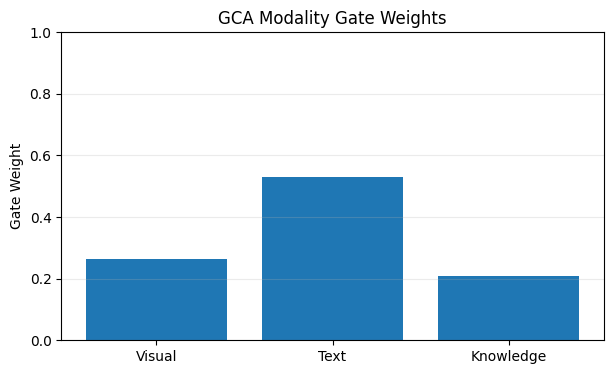

EXPLAINABILITY REPORT

GCA Modality Gates:
Visual:    0.2632
Text:      0.5289
Knowledge: 0.2079

GAT Contribution (alpha): 0.2015

Personalized Recommendation Explanation:


,Rank,Hashtag,Model Score,Preference Boost,Final Score,Explanation
0,1,#man,0.7869,0.00,0.7475,Selected mainly by content relevance
1,2,#wearing,0.4917,0.00,0.4671,Selected mainly by content relevance
2,3,#shirt,0.2519,0.05,0.2893,Preferred by user
3,4,#green,0.2540,0.00,0.2413,Selected mainly by content relevance
4,5,#blue,0.1052,0.05,0.1500,Preferred by user



Note: Gate weights and alpha describe internal model
behavior; they are not causal feature attributions.


In [49]:

# ============================================================
# FINAL MODULE — CELL 2
# EXPLAINABILITY + VISUALIZATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

USER_ID = "user_2"
SAMPLE_ID = 0
LAMBDA = 0.05

gat_gca_model.eval()

# Find the selected sample in the validation loader
sample_graph = None
offset = 0

with torch.no_grad():
    for batch in val_graph_loader:
        batch_size = batch.y.shape[0]

        if offset <= SAMPLE_ID < offset + batch_size:
            batch = batch.to(GAT_DEVICE)

            logits, gate_weights, attention_weights, fused_kg, gat_kg, alpha = (
                gat_gca_model(
                    batch.visual,
                    batch.text,
                    batch.static_kg,
                    batch.x,
                    batch.edge_index,
                    batch.batch
                )
            )

            local_idx = SAMPLE_ID - offset
            sample_graph = True
            break

        offset += batch_size

assert sample_graph is not None, "Sample not found."

# Extract GCA modality gates
gates = gate_weights[local_idx].detach().cpu().numpy().reshape(-1)

assert len(gates) == 3, "Expected 3 modality gates."

# Extract GAT alpha
alpha_value = float(
    alpha.detach().cpu().reshape(-1).mean()
)

# Explain personalized hashtag ranking
model_scores = torch.sigmoid(
    logits[local_idx]
).detach().cpu().numpy()

results, _ = personalize_hashtags(
    model_scores,
    USER_ID,
    top_k=5,
    candidate_k=15,
    personalization_weight=LAMBDA
)

explanation_rows = []

for rank, item in enumerate(results, 1):
    preference_boost = LAMBDA * item["user_preference"]

    explanation_rows.append({
        "Rank": rank,
        "Hashtag": item["hashtag"],
        "Model Score": round(item["model_score"], 4),
        "Preference Boost": round(preference_boost, 4),
        "Final Score": round(item["personalized_score"], 4),
        "Explanation": (
            "Preferred by user"
            if item["user_preference"] > 0
            else "Selected mainly by content relevance"
        )
    })

explanation_df = pd.DataFrame(explanation_rows)

# Visualize modality gate weights
plt.figure(figsize=(7, 4))
plt.bar(
    ["Visual", "Text", "Knowledge"],
    gates
)
plt.title("GCA Modality Gate Weights")
plt.ylabel("Gate Weight")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.25)
plt.show()

print("=" * 60)
print("EXPLAINABILITY REPORT")
print("=" * 60)

print("\nGCA Modality Gates:")
print(f"Visual:    {gates[0]:.4f}")
print(f"Text:      {gates[1]:.4f}")
print(f"Knowledge: {gates[2]:.4f}")

print(f"\nGAT Contribution (alpha): {alpha_value:.4f}")

print("\nPersonalized Recommendation Explanation:")
display(explanation_df)

print("\nNote: Gate weights and alpha describe internal model")
print("behavior; they are not causal feature attributions.")
